<h1 style="text-align: center;">Tutorial: Clustering</h1>


## Introducción
El clustering o agrupamiento es una técnica de aprendizaje no supervisado que permite identificar grupos de observaciones con características similares. A diferencia de los métodos de clasificación supervisada, en este caso el algoritmo no utiliza una variable de respuesta para aprender a qué grupo pertenece cada observación.

En este tutorial se utilizarán dos métodos de agrupamiento: K-means y clustering jerárquico. Primero se trabajará con una base de datos sintética para observar cómo K-means asigna las observaciones a distintos grupos y actualiza sus centroides. Posteriormente, se utilizará la base de datos NCI60, que contiene información sobre la expresión de genes en distintas líneas celulares de cáncer.

También se aplicará el análisis de componentes principales (PCA) para reducir la cantidad de variables y facilitar la visualización de los datos. Finalmente, se construirán dendrogramas y se compararán diferentes formas de calcular la distancia entre observaciones y grupos.

El objetivo de este tutorial es explicar de manera clara y reproducible cómo funcionan estos métodos, cómo se aplican y qué información pueden proporcionar los grupos obtenidos.

## Parte 1. K-Means Clustering

### Paso 1. Importación de librerías
Para comenzar, se importarán las librerías necesarias para generar y manipular los datos, realizar operaciones numéricas y construir las visualizaciones.

También se importará la función make_blobs, que permitirá crear una base de datos sintética con grupos conocidos. Esta base se utilizará para entender el funcionamiento de K-means antes de aplicarlo a datos reales.


In [2]:
# Manipulación de datos y operaciones numéricas
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Generación de datos sintéticos
from sklearn.datasets import make_blobs

# Configuración general de las gráficas
sns.set_theme(style="whitegrid")

### Paso 2. Creación de la base de datos sintética
Para observar cómo se forman los grupos, se generará una base de datos sintética utilizando make_blobs. Esta función permite crear observaciones alrededor de distintos centros.

Se generarán 1,000 observaciones, con dos variables, tres centros y una desviación estándar de 1.5. Aunque la función también genera una etiqueta que indica el centro de origen de cada observación, por ahora no se utilizará en la gráfica. Esto permite observar los datos sin mostrar los grupos de antemano, como ocurriría en un problema no supervisado.

In [3]:
# Generar la base de datos sintética
X, etiquetas_originales = make_blobs(
    n_samples=1000,
    centers=3,
    n_features=2,
    cluster_std=1.5,
    random_state=27
)

# Convertir los datos en un DataFrame
datos = pd.DataFrame(X, columns=["Variable 1", "Variable 2"])

# Revisar las primeras observaciones
display(datos.head())

print(f"Número de observaciones: {datos.shape[0]}")
print(f"Número de variables: {datos.shape[1]}")

,Variable 1,Variable 2
0,5.645858,3.909286
1,-0.929138,10.075357
2,-1.214923,8.739354
3,-3.118774,6.680903
4,-2.484911,6.558291


Número de observaciones: 1000
Número de variables: 2


La semilla random_state=27 permite que los datos generados sean los mismos cada vez que se ejecute esta celda. Más adelante se modificará la asignación inicial de los grupos para observar cómo puede cambiar el resultado.

### Paso 3. Visualización de los datos
Antes de aplicar K-means, se graficarán las dos variables para observar cómo se distribuyen las 1,000 observaciones.

En esta primera gráfica todos los puntos tendrán el mismo color, ya que todavía no se ha realizado el agrupamiento.

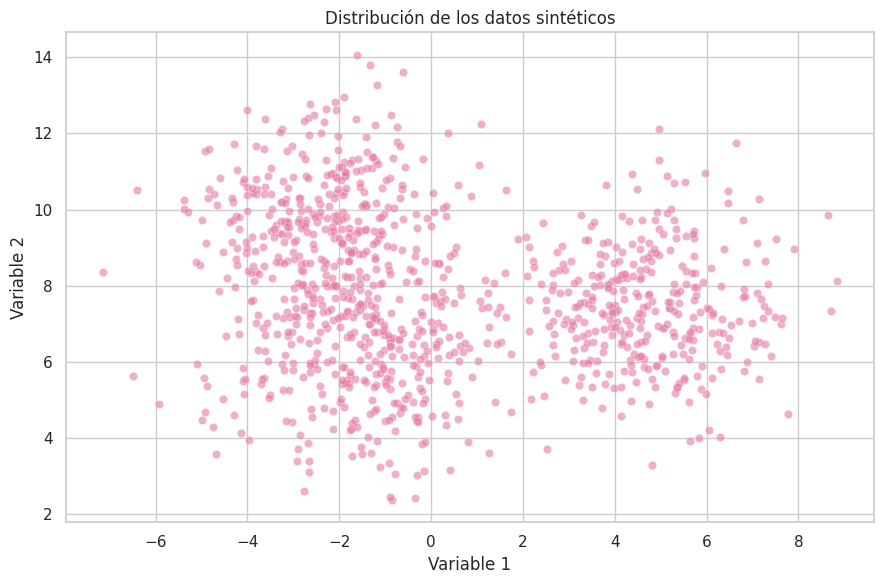

In [4]:
plt.figure(figsize=(9, 6))

plt.scatter(
    datos["Variable 1"],
    datos["Variable 2"],
    color="#E77BA5",
    alpha=0.6,
    edgecolor="white",
    linewidth=0.3
)

plt.title("Distribución de los datos sintéticos")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.tight_layout()
plt.show()

En la gráfica se puede observar la distribución de las observaciones a partir de sus dos variables. Es posible que algunas zonas concentren más puntos que otras, lo que sugiere la presencia de grupos. Sin embargo, todavía no se ha asignado cada observación a un cluster.

El siguiente paso sería asignar aleatoriamente cada observación a uno de los tres clusters, calcular sus centroides y comenzar a actualizar las asignaciones. Así podremos construir K-means paso a paso antes de usar la función de scikit-learn.

### Paso 4. Asignación inicial de clusters
El algoritmo K-means busca agrupar observaciones de acuerdo con su cercanía. Para entender el proceso, primero se asignará cada observación de manera aleatoria a uno de tres clusters.

En esta primera asignación todavía no se considera la posición de los puntos. Por lo tanto, es normal que las observaciones de un mismo grupo aparezcan dispersas en la gráfica.

Se utilizará una semilla para que la asignación sea reproducible, es decir, para que se obtengan los mismos grupos iniciales cada vez que se ejecute la celda.

In [5]:
# Semilla para reproducir la asignación inicial
np.random.seed(27)

# Número de clusters
k = 3

# Asignar aleatoriamente cada observación a un cluster
datos["Cluster"] = np.random.randint(0, k, size=len(datos))

# Revisar las primeras observaciones
display(datos.head())

# Mostrar cuántas observaciones se asignaron a cada cluster
print("Cantidad de observaciones por cluster:")
print(datos["Cluster"].value_counts().sort_index())

,Variable 1,Variable 2,Cluster
0,5.645858,3.909286,0
1,-0.929138,10.075357,0
2,-1.214923,8.739354,0
3,-3.118774,6.680903,0
4,-2.484911,6.558291,1


Cantidad de observaciones por cluster:
Cluster
0    329
1    322
2    349
Name: count, dtype: int64


Ahora se graficarán las observaciones utilizando un color diferente para cada cluster.

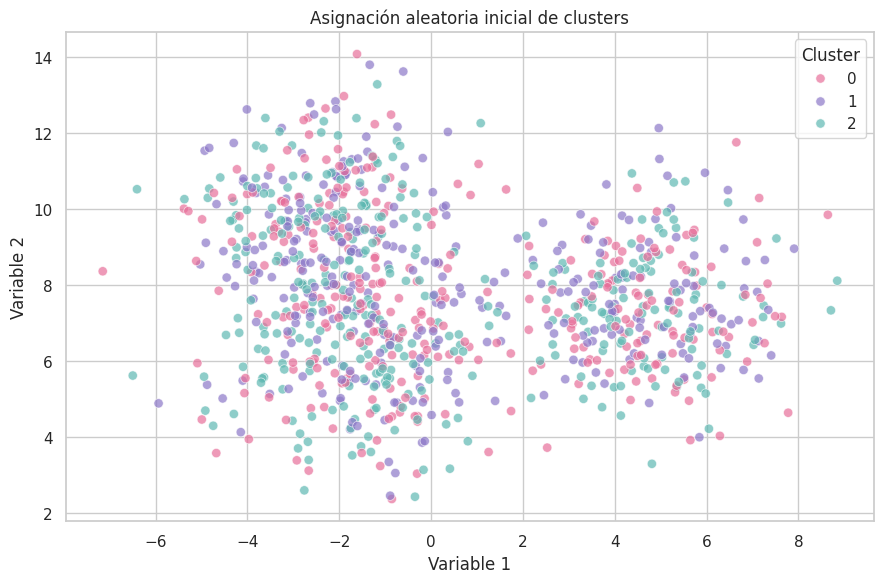

In [6]:
# Colores para los tres clusters
colores = ["#E76F9A", "#8C78C8", "#5EB8B2"]

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=datos,
    x="Variable 1",
    y="Variable 2",
    hue="Cluster",
    palette=colores,
    alpha=0.7,
    s=45
)

plt.title("Asignación aleatoria inicial de clusters")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

En la gráfica se observa que los puntos rosas, morados y verdes están mezclados en diferentes partes del plano. Esto ocurre porque la asignación inicial se realizó de manera aleatoria, sin considerar la distancia entre las observaciones.

Aunque visualmente se pueden distinguir zonas con mayor concentración de puntos, los colores todavía no representan grupos formados según su cercanía. Por ejemplo, dentro de la concentración de puntos ubicada a la derecha hay observaciones de los tres colores.

### Paso 5. Cálculo de los centroides iniciales
Un centroide representa el centro de un cluster. En K-means se obtiene calculando el promedio de cada variable para las observaciones que pertenecen al mismo grupo.

Por ejemplo, si un cluster tiene varias observaciones, su centroide tendrá:
- Un valor promedio para la Variable 1.
- Un valor promedio para la Variable 2.

Estos dos valores indican la posición del centroide en la gráfica.

In [7]:
# Calcular el promedio de cada variable por cluster
centroides = datos.groupby("Cluster")[["Variable 1", "Variable 2"]].mean()

print("Centroides iniciales:")
display(centroides)

Centroides iniciales:


,Variable 1,Variable 2
Cluster,,
0,0.472860,7.651350
1,0.300885,8.070636
2,0.112088,7.661668


Ahora se mostrarán los centroides sobre la gráfica. Las X negras representan el centro de cada cluster.

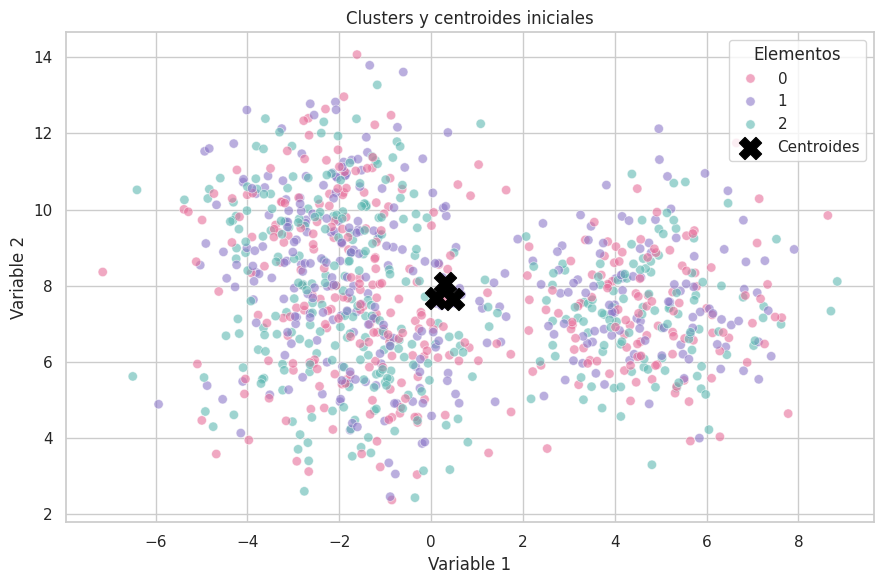

In [8]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=datos,
    x="Variable 1",
    y="Variable 2",
    hue="Cluster",
    palette=colores,
    alpha=0.6,
    s=45
)

# Graficar los centroides
plt.scatter(
    centroides["Variable 1"],
    centroides["Variable 2"],
    color="black",
    marker="X",
    s=250,
    label="Centroides"
)

plt.title("Clusters y centroides iniciales")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.legend(title="Elementos")
plt.tight_layout()
plt.show()

Las X negras representan los centroides calculados a partir de la asignación aleatoria. Cada centroide corresponde al promedio de las dos variables para las observaciones de su cluster.

En la gráfica, las tres X aparecen muy juntas y casi se enciman. Esto sucede porque los puntos de cada color están distribuidos por todo el plano: al calcular sus promedios, los centros de los tres grupos quedan en posiciones parecidas.

Por lo tanto, en esta etapa los centroides todavía no representan claramente las zonas donde se concentran los datos.

### Paso 6. Reasignación de las observaciones
Una vez calculados los centroides iniciales, se revisará qué centroide está más cerca de cada observación. Después, cada punto se asignará al cluster correspondiente a su centroide más cercano.

Para medir la cercanía se utilizará la distancia euclidiana, que representa la distancia en línea recta entre dos puntos.

Por ejemplo, si una observación está más cerca del centroide del cluster 1 que de los otros dos centroides, se asignará al cluster 1.

In [9]:
# Obtener las coordenadas de las observaciones y los centroides
puntos = datos[["Variable 1", "Variable 2"]].to_numpy()
centros = centroides.to_numpy()

# Calcular la distancia de cada observación a cada centroide
distancias = np.sqrt(
    ((puntos[:, np.newaxis, :] - centros[np.newaxis, :, :]) ** 2).sum(axis=2)
)

# Asignar cada observación al cluster de su centroide más cercano
datos["Cluster"] = distancias.argmin(axis=1)

# Mostrar la nueva cantidad de observaciones por cluster
print("Observaciones por cluster después de la reasignación:")
print(datos["Cluster"].value_counts().sort_index())

Observaciones por cluster después de la reasignación:
Cluster
0    343
1    270
2    387
Name: count, dtype: int64


En la variable distancias, cada fila corresponde a una observación y cada columna corresponde a uno de los centroides. La función argmin() identifica la columna que contiene la distancia más pequeña para cada observación.

### Paso 7. Actualización de los centroides
Después de reasignar los puntos, los centroides anteriores ya no representan necesariamente el centro de sus nuevos grupos. Por eso, se vuelve a calcular el promedio de cada variable para cada cluster.

In [10]:
# Calcular los nuevos centroides
centroides = datos.groupby("Cluster")[["Variable 1", "Variable 2"]].mean()

print("Centroides después de la primera actualización:")
display(centroides)

Centroides después de la primera actualización:


,Variable 1,Variable 2
Cluster,,
0,4.275751,7.060299
1,-1.263178,10.322190
2,-2.154909,6.669993


Ahora se graficarán los clusters y los centroides actualizados.

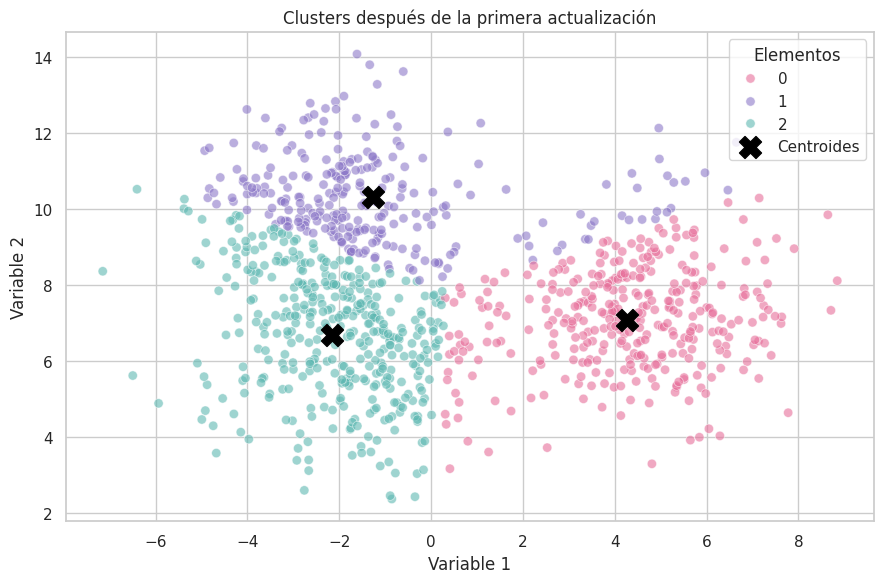

In [11]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=datos,
    x="Variable 1",
    y="Variable 2",
    hue="Cluster",
    palette=colores,
    alpha=0.6,
    s=45
)

plt.scatter(
    centroides["Variable 1"],
    centroides["Variable 2"],
    color="black",
    marker="X",
    s=250,
    label="Centroides"
)

plt.title("Clusters después de la primera actualización")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.legend(title="Elementos")
plt.tight_layout()
plt.show()

Después de asignar cada punto al centroide inicial más cercano y calcular nuevamente los promedios, los centroides se desplazaron hacia distintas zonas de la gráfica. Ahora se observa un grupo rosa principalmente a la derecha, uno morado en la parte superior y uno verde en la parte inferior izquierda.

En comparación con la asignación inicial, los colores comienzan a organizarse de acuerdo con la cercanía entre los puntos. Sin embargo, todavía se observan algunas asignaciones que pueden cambiar; por ejemplo, hay puntos morados en la parte superior derecha, cerca del grupo rosa.

Por eso, el proceso debe repetirse: en cada iteración se vuelven a asignar las observaciones al centroide más cercano y se actualizan los centroides, hasta que las asignaciones dejan de cambiar o se alcanza el límite de iteraciones.

### Paso 8. Repetición del proceso hasta la convergencia
El procedimiento anterior se repite de la siguiente manera:
1. Se calcula la distancia de cada observación a los centroides.
2. Cada observación se asigna al centroide más cercano.
3. Se calculan nuevamente los centroides.
4. Se revisa si las asignaciones cambiaron.

El proceso se detiene cuando las observaciones dejan de cambiar de cluster o cuando se alcanza el número máximo de iteraciones establecido.

La siguiente celda continúa desde los grupos obtenidos en el paso anterior.

In [12]:
# Establecer un límite de iteraciones
max_iteraciones = 100

# Repetir el proceso de asignación y actualización
for iteracion in range(max_iteraciones):

    # Guardar las asignaciones antes de actualizarlas
    clusters_anteriores = datos["Cluster"].to_numpy().copy()

    # Obtener las coordenadas actuales de los centroides
    centros = centroides.to_numpy()

    # Calcular la distancia de cada observación a cada centroide
    distancias = np.sqrt(
        ((puntos[:, np.newaxis, :] - centros[np.newaxis, :, :]) ** 2).sum(axis=2)
    )

    # Asignar cada observación al centroide más cercano
    datos["Cluster"] = distancias.argmin(axis=1)

    # Calcular los nuevos centroides
    centroides = datos.groupby("Cluster")[["Variable 1", "Variable 2"]].mean()

    # Contar cuántas observaciones cambiaron de cluster
    cambios = np.sum(clusters_anteriores != datos["Cluster"].to_numpy())

    print(f"Iteración {iteracion + 1}: {cambios} observaciones cambiaron de cluster")

    # Detener el proceso si las asignaciones ya no cambian
    if cambios == 0:
        print("\nEl algoritmo convergió.")
        break
else:
    print("\nSe alcanzó el límite máximo de iteraciones.")

Iteración 1: 91 observaciones cambiaron de cluster
Iteración 2: 46 observaciones cambiaron de cluster
Iteración 3: 19 observaciones cambiaron de cluster
Iteración 4: 8 observaciones cambiaron de cluster
Iteración 5: 8 observaciones cambiaron de cluster
Iteración 6: 0 observaciones cambiaron de cluster

El algoritmo convergió.


Nota: El número de iteraciones que aparece aquí corresponde a las repeticiones realizadas en esta celda. La primera actualización ya se había realizado en los pasos 6 y 7.

### Paso 9. Visualización de los clusters finales
Una vez que el proceso termina, se graficarán las observaciones con sus asignaciones finales y la ubicación de los centroides.

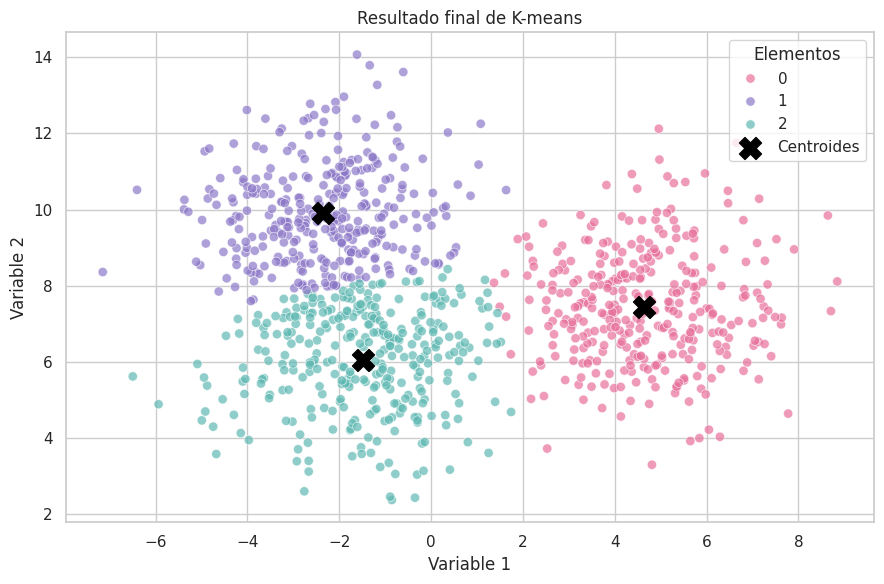

Centroides finales:


,Variable 1,Variable 2
Cluster,,
0,4.643140,7.428680
1,-2.345837,9.897139
2,-1.475008,6.048417


Cantidad final de observaciones por cluster:
Cluster
0    336
1    332
2    332
Name: count, dtype: int64


In [13]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=datos,
    x="Variable 1",
    y="Variable 2",
    hue="Cluster",
    palette=colores,
    alpha=0.7,
    s=45
)

plt.scatter(
    centroides["Variable 1"],
    centroides["Variable 2"],
    color="black",
    marker="X",
    s=250,
    label="Centroides"
)

plt.title("Resultado final de K-means")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.legend(title="Elementos")
plt.tight_layout()
plt.show()

print("Centroides finales:")
display(centroides)

print("Cantidad final de observaciones por cluster:")
print(datos["Cluster"].value_counts().sort_index())

En la gráfica se observan tres grupos de observaciones diferenciados por color. El cluster 0, de color rosa, se encuentra principalmente en la parte derecha; el cluster 1, de color morado, en la parte superior izquierda; y el cluster 2, de color verde, en la parte inferior izquierda.

Las X negras representan los centroides de cada grupo. Estos indican el promedio de las posiciones de las observaciones que pertenecen a cada cluster. En general, los puntos de cada color se encuentran alrededor de su centroide, aunque existe cierta cercanía entre los grupos morado y verde.

El resultado muestra que, después de repetir las asignaciones y actualizaciones, K-means agrupó las observaciones según su cercanía. Sin embargo, las observaciones cercanas a los límites entre grupos podrían cambiar de cluster si varían los centroides.

### Paso 10. Evaluación de la variación dentro de los clusters
Para evaluar qué tan compactos son los grupos, se puede calcular la suma de las distancias al cuadrado entre cada observación y el centroide de su cluster. Esta medida también se conoce como inercia o within-cluster sum of squares.

Un valor menor indica que, en conjunto, las observaciones están más cerca de los centroides de sus respectivos grupos. Esta medida será útil para comparar distintas ejecuciones con el mismo número de clusters.

In [14]:
# Obtener el centroide correspondiente a cada observación
centroide_por_observacion = centroides.loc[
    datos["Cluster"].to_numpy()
].to_numpy()

# Calcular la suma de distancias al cuadrado
inercia = np.sum((puntos - centroide_por_observacion) ** 2)

print(f"Variación dentro de los clusters (inercia): {inercia:.2f}")

Variación dentro de los clusters (inercia): 3841.18


El valor obtenido resume la distancia de las observaciones a sus centroides. Por sí solo no determina si los grupos son buenos o malos, resulta más útil cuando se compara con otras ejecuciones bajo las mismas condiciones.

### Paso 11. Efecto de la asignación aleatoria inicial
K-means puede llegar a distintas soluciones según cómo se inicialicen los grupos. Para observarlo, se repetirá el proceso sin fijar una semilla, de modo que la asignación inicial pueda cambiar en cada ejecución.

Se guardará primero el resultado anterior para poder comparar la variación obtenida en ambos casos.

In [15]:
# Guardar el resultado obtenido con la asignación reproducible
inercia_con_semilla = inercia

# Crear una nueva asignación inicial sin fijar semilla
generador = np.random.default_rng()

datos["Cluster"] = generador.integers(0, k, size=len(datos))

# Calcular los centroides a partir de la nueva asignación
centroides = datos.groupby("Cluster")[["Variable 1", "Variable 2"]].mean()

# Repetir el proceso
for iteracion in range(max_iteraciones):

    clusters_anteriores = datos["Cluster"].to_numpy().copy()

    centros = centroides.to_numpy()

    distancias = np.sqrt(
        ((puntos[:, np.newaxis, :] - centros[np.newaxis, :, :]) ** 2).sum(axis=2)
    )

    datos["Cluster"] = distancias.argmin(axis=1)

    centroides = datos.groupby("Cluster")[["Variable 1", "Variable 2"]].mean()

    cambios = np.sum(clusters_anteriores != datos["Cluster"].to_numpy())

    if cambios == 0:
        break

# Calcular la inercia de la nueva ejecución
centroide_por_observacion = centroides.loc[
    datos["Cluster"].to_numpy()
].to_numpy()

inercia_sin_semilla = np.sum((puntos - centroide_por_observacion) ** 2)

# Comparar los resultados
comparacion = pd.DataFrame({
    "Ejecución": [
        "Asignación inicial con semilla",
        "Asignación inicial sin semilla"
    ],
    "Inercia": [
        inercia_con_semilla,
        inercia_sin_semilla
    ]
})

display(comparacion)

,Ejecución,Inercia
0,Asignación inicial con semilla,3841.180902
1,Asignación inicial sin semilla,3841.180902


La ejecución con semilla obtuvo una inercia de 3841.180902, mientras que la ejecución sin semilla obtuvo una inercia de 3841.173498. La diferencia entre ambas es de aproximadamente 0.0074, por lo que los resultados son muy similares.

En esta comparación, la ejecución sin semilla obtuvo una inercia ligeramente menor. Esto significa que la suma de las distancias al cuadrado entre los puntos y sus centroides fue un poco menor, aunque la diferencia es tan pequeña que no representa un cambio importante en la agrupación.

Finalmente, se visualizará el resultado de la nueva ejecución.

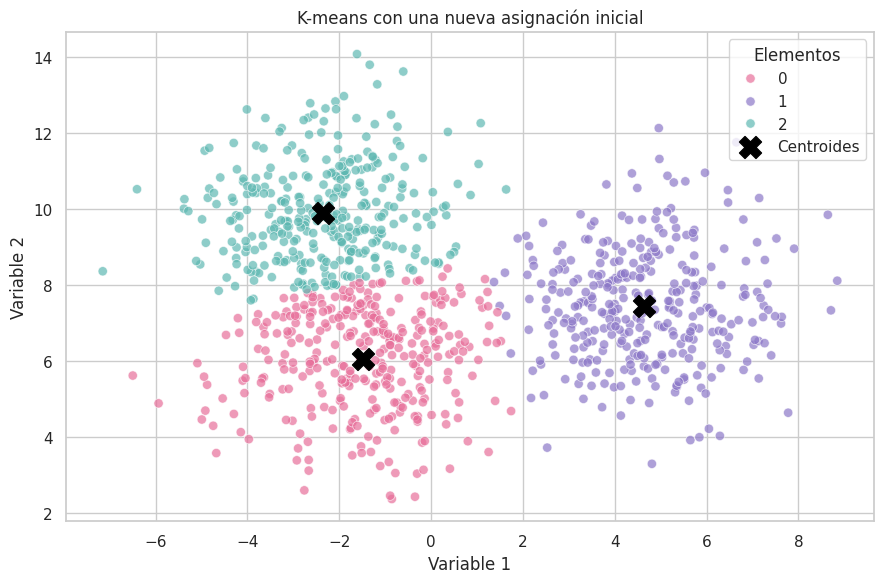

In [16]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=datos,
    x="Variable 1",
    y="Variable 2",
    hue="Cluster",
    palette=colores,
    alpha=0.7,
    s=45
)

plt.scatter(
    centroides["Variable 1"],
    centroides["Variable 2"],
    color="black",
    marker="X",
    s=250,
    label="Centroides"
)

plt.title("K-means con una nueva asignación inicial")
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.legend(title="Elementos")
plt.tight_layout()
plt.show()

En esta gráfica se observa prácticamente la misma distribución de grupos que en la primera: un grupo a la derecha, otro en la parte superior izquierda y otro en la parte inferior izquierda. Las posiciones de los centroides también son muy parecidas.

Lo que sí cambió fue el color y el número de cada grupo. Por ejemplo, el grupo de la derecha pasó de ser el cluster 0 de color rosa al cluster 2 de color verde. Esto ocurre porque los números de los clusters son etiquetas que asigna el algoritmo; no tienen un significado fijo entre una ejecución y otra.

En este caso, las dos inicializaciones produjeron resultados muy parecidos. Esto no significa que siempre vaya a ocurrir: con otras asignaciones iniciales o con datos diferentes, K-means podría llegar a una solución distinta.

## Parte 2. K-Means en la base de datos

### Paso 12. Carga de la base de datos NCI60
En esta parte se utilizará la base de datos NCI60, incluida en la librería ISLP. Esta base contiene mediciones de expresión genética de distintas líneas celulares de cáncer.

Cada fila representa una línea celular y cada columna corresponde a una medición de expresión de un gen. También se incluyen etiquetas que identifican el tipo de cáncer asociado con cada observación.

El objetivo será agrupar las líneas celulares según la similitud de su expresión genética. Las etiquetas de cáncer no se utilizarán para formar los clusters, posteriormente servirán para interpretar los grupos obtenidos.

In [17]:
%pip install ISLP

from ISLP import load_data
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Cargar la base de datos
nci60 = load_data("NCI60")

# Separar las mediciones de expresión genética y las etiquetas
X_nci = pd.DataFrame(nci60["data"]).copy()

# Convertir las etiquetas en un arreglo de una dimensión
etiquetas_cancer = pd.Series(
    np.asarray(nci60["labels"]).ravel(),
    index=X_nci.index,
    name="Tipo de cáncer"
)

# Mostrar una parte de los datos
display(X_nci.iloc[:5, :8])

print(f"Número de líneas celulares: {X_nci.shape[0]}")
print(f"Número de variables de expresión genética: {X_nci.shape[1]}")
print(f"Valores faltantes: {X_nci.isna().sum().sum()}")

,0,1,2,3,4,5,6,7
0,0.300000,1.180000,0.550000,1.140000,-0.265000,-7.000000e-02,0.350000,-0.315000
1,0.679961,1.289961,0.169961,0.379961,0.464961,5.799610e-01,0.699961,0.724961
2,0.940000,-0.040000,-0.170000,-0.040000,-0.605000,0.000000e+00,0.090000,0.645000
3,0.280000,-0.310000,0.680000,-0.810000,0.625000,-1.387779e-17,0.170000,0.245000
4,0.485000,-0.465000,0.395000,0.905000,0.200000,-5.000000e-03,0.085000,0.110000


Número de líneas celulares: 64
Número de variables de expresión genética: 6830
Valores faltantes: 0


Las dimensiones permiten identificar cuántas líneas celulares y variables contiene la base. La revisión de valores faltantes ayuda a determinar si es necesario realizar algún tratamiento antes de aplicar el agrupamiento.

### Paso 13. Exploración de las etiquetas
Se contará cuántas observaciones corresponden a cada tipo de cáncer. Esto permitirá conocer la composición de la base antes de interpretar los clusters.

In [19]:
# Contar las observaciones de cada tipo de cáncer
conteo_cancer = (
    etiquetas_cancer.value_counts()
    .rename_axis("Tipo de cáncer")
    .reset_index(name="Número de observaciones")
)

display(conteo_cancer)

,Tipo de cáncer,Número de observaciones
0,RENAL,9
1,NSCLC,9
2,MELANOMA,8
3,BREAST,7
4,COLON,7
5,OVARIAN,6
6,LEUKEMIA,6
7,CNS,5
8,PROSTATE,2
9,UNKNOWN,1


Para facilitar la comparación, se graficarán las cantidades:

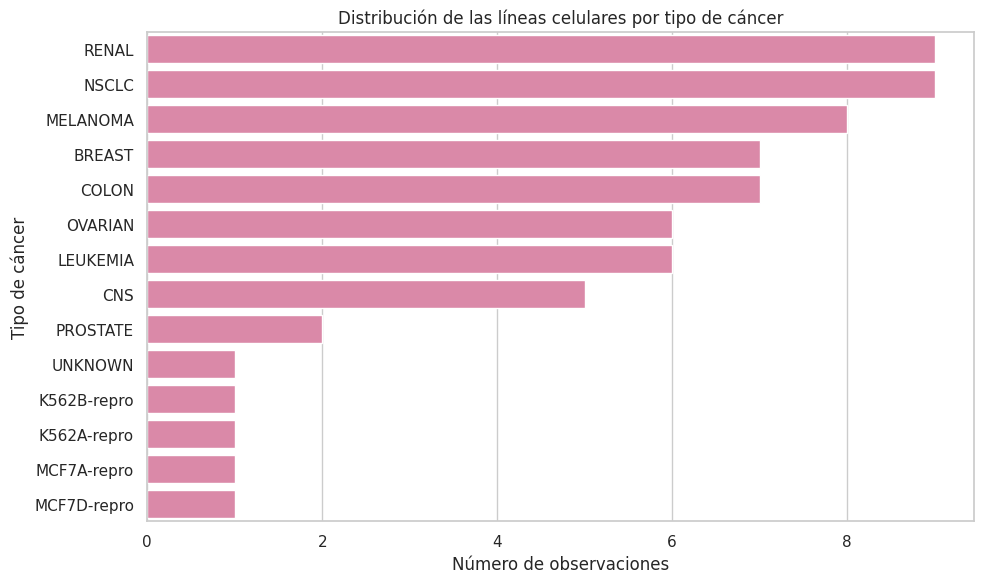

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=conteo_cancer,
    x="Número de observaciones",
    y="Tipo de cáncer",
    color="#E77BA5"
)

plt.title("Distribución de las líneas celulares por tipo de cáncer")
plt.xlabel("Número de observaciones")
plt.ylabel("Tipo de cáncer")
plt.tight_layout()
plt.show()

La gráfica muestra que las categorías RENAL y NSCLC tienen la mayor cantidad de líneas celulares, con 9 observaciones cada una, seguidas de MELANOMA, con 8. En cambio, PROSTATE cuenta con 2, mientras que UNKNOWN y cada etiqueta terminada en "repro" tienen una sola observación.

Esto indica que las categorías no están representadas por igual. Al comparar las etiquetas con los clusters, será necesario considerar estas diferencias: encontrar más observaciones de una categoría dentro de un grupo podría deberse a que esa categoría es más abundante en la base. Además, las etiquetas «repro» corresponden a reproducciones de líneas celulares y UNKNOWN indica una categoría desconocida; no deben interpretarse como tipos de cáncer adicionales.

### Paso 14. Estandarización de las variables
K-means utiliza distancias para formar los grupos. Por eso, las variables con mayor dispersión pueden tener más influencia en el resultado.

En este tutorial se estandarizarán las mediciones de expresión genética para que cada variable tenga una media cercana a cero y una desviación estándar de uno. Esta decisión permite que el agrupamiento considere las diferencias relativas de cada gen.

In [21]:
# Crear el estandarizador
escalador_nci = StandardScaler()

# Estandarizar las variables de expresión genética
X_nci_estandarizado = escalador_nci.fit_transform(X_nci)

# Conservar nombres de columnas e índices
X_nci_std = pd.DataFrame(
    X_nci_estandarizado,
    index=X_nci.index,
    columns=X_nci.columns
)

# Revisar una parte de los datos transformados
display(X_nci_std.iloc[:5, :8])

,0,1,2,3,4,5,6,7
0,0.728671,1.607220,1.325688,1.355688,-0.604845,-0.220654,0.898137,-0.868741
1,1.596418,1.753544,0.441686,0.654119,0.911898,1.648748,1.849697,2.226625
2,2.190290,-0.016217,-0.349092,0.266465,-1.311310,-0.019322,0.191185,1.988627
3,0.682995,-0.375502,1.628079,-0.444299,1.244434,-0.019322,0.408709,0.798057
4,1.151170,-0.581759,0.965145,1.138767,0.361351,-0.033703,0.177590,0.396239


Los valores transformados indican qué tan por encima o por debajo del promedio se encuentra una medición para cada gen. Los valores negativos no representan una expresión genética negativa, solo indican una medición inferior al promedio de esa variable.

### Paso 15. Aplicación de K-means
Ahora, se probarán tres, cuatro y cinco clusters, utilizando n_init=30.

El parámetro n_init indica cuántas inicializaciones diferentes probará K-means. El algoritmo conservará la solución con menor inercia entre esas ejecuciones.

In [22]:
# Guardar los modelos y sus resultados
modelos_nci = {}
resultados_nci = []

for k_nci in [3, 4, 5]:

    modelo = KMeans(
        n_clusters=k_nci,
        n_init=30,
        random_state=42
    )

    clusters = modelo.fit_predict(X_nci_std)

    modelos_nci[k_nci] = modelo

    resultados_nci.append({
        "Número de clusters": k_nci,
        "Inercia": modelo.inertia_,
        "Iteraciones de la mejor ejecución": modelo.n_iter_
    })

# Mostrar la comparación
tabla_kmeans_nci = pd.DataFrame(resultados_nci)

display(
    tabla_kmeans_nci.style
    .format({"Inercia": "{:,.2f}"})
    .hide(axis="index")
    .set_caption("K-means sobre las variables genéticas estandarizadas")
)

Número de clusters,Inercia,Iteraciones de la mejor ejecución
3,"372,673.43",5
4,"350,281.66",5
5,"336,620.62",4


La tabla muestra la inercia obtenida con cada número de clusters. Generalmente, esta disminuye al aumentar la cantidad de grupos porque existen más centroides para representar las observaciones. Por ello, una inercia menor con cinco clusters no basta para afirmar que esa es la mejor elección.

Por ahora, se utilizarán cuatro clusters como una elección inicial que se revisará posteriormente con las visualizaciones de PCA.

In [23]:
# Selección inicial para continuar el análisis
k_inicial = 4

modelo_nci_original = modelos_nci[k_inicial]
clusters_nci_original = modelo_nci_original.labels_

# Contar observaciones por cluster
conteo_clusters_nci = (
    pd.Series(clusters_nci_original, name="Cluster")
    .value_counts()
    .sort_index()
    .rename_axis("Cluster")
    .reset_index(name="Número de observaciones")
)

display(conteo_clusters_nci)

,Cluster,Número de observaciones
0,0,8
1,1,35
2,2,9
3,3,12


### Paso 16. Visualización de pares de variables
Para observar los clusters, se graficarán algunos pares de las variables originales estandarizadas.

Aunque cada gráfica muestra únicamente dos variables, K-means utilizó todas las variables genéticas para formar los grupos. Por eso, es posible que los colores se mezclen en estas visualizaciones.

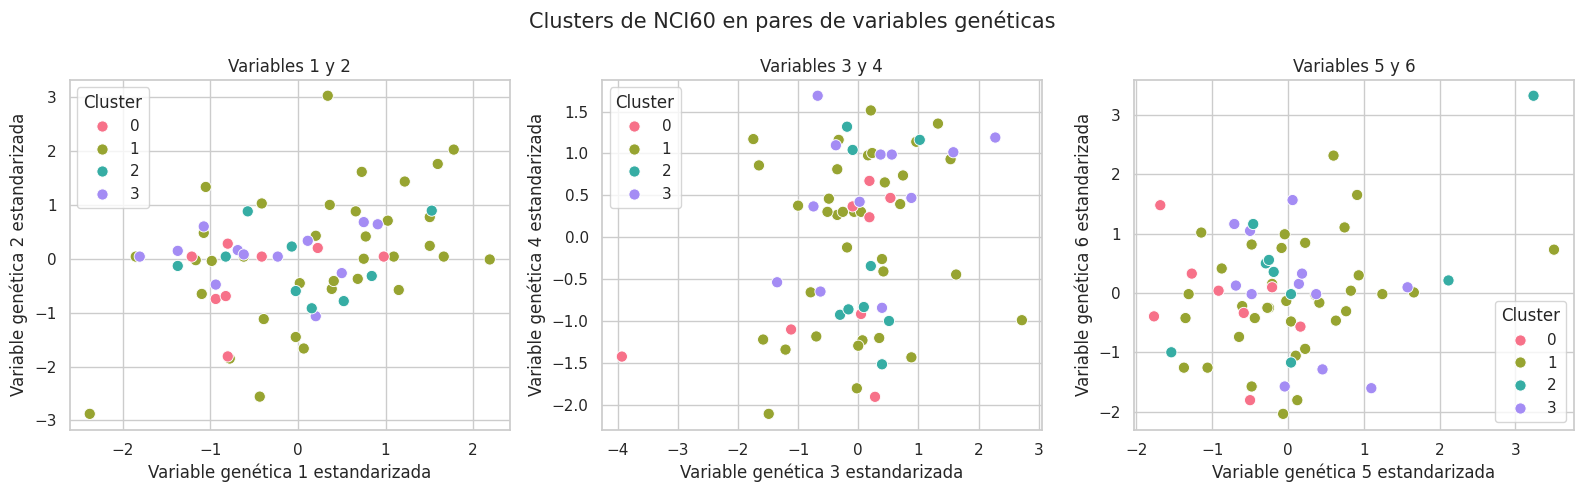

In [24]:
# Seleccionar tres pares de variables
pares_genes = [(0, 1), (2, 3), (4, 5)]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (i, j) in zip(axes, pares_genes):

    sns.scatterplot(
        x=X_nci_std.iloc[:, i].to_numpy(),
        y=X_nci_std.iloc[:, j].to_numpy(),
        hue=clusters_nci_original,
        palette=sns.color_palette("husl", n_colors=k_inicial),
        s=65,
        edgecolor="white",
        ax=ax
    )

    ax.set_xlabel(f"Variable genética {i + 1} estandarizada")
    ax.set_ylabel(f"Variable genética {j + 1} estandarizada")
    ax.set_title(f"Variables {i + 1} y {j + 1}")
    ax.legend(title="Cluster")

fig.suptitle(
    "Clusters de NCI60 en pares de variables genéticas",
    fontsize=15
)

plt.tight_layout()
plt.show()

En las tres gráficas se observa que los puntos de los cuatro clusters aparecen mezclados, sin una separación clara por colores. El cluster 1, de color verde, presenta una dispersión amplia, mientras que los demás clusters comparten varias de las mismas zonas.

Esto indica que los pares de variables 1 y 2, 3 y 4, y 5 y 6 no son suficientes para distinguir visualmente los grupos. Sin embargo, no significa que el agrupamiento sea incorrecto, porque K-means utilizó todas las variables genéticas para calcular las asignaciones.

Por esta razón, se aplicará PCA para resumir la información de múltiples variables y explorar si los grupos se distinguen mejor al graficar los componentes principales.

### Paso 17. Aplicación de PCA
La base NCI60 contiene muchas variables genéticas, lo que dificulta visualizar las observaciones. Para resumir esta información se utilizará el análisis de componentes principales (PCA).

PCA crea nuevas variables llamadas componentes principales. Cada componente combina las variables originales, y los primeros componentes concentran la mayor parte de la variación de los datos.

Se utilizarán los datos estandarizados del paso anterior.

In [25]:
# Ajustar PCA sobre las variables genéticas estandarizadas
pca_nci = PCA(svd_solver="full")

componentes_nci = pca_nci.fit_transform(X_nci_std)

# Organizar los componentes en un DataFrame
df_pca_nci = pd.DataFrame(
    componentes_nci,
    index=X_nci_std.index,
    columns=[
        f"PC{i + 1}"
        for i in range(componentes_nci.shape[1])
    ]
)

# Mostrar los primeros tres componentes
display(df_pca_nci.iloc[:5, :3])

,PC1,PC2,PC3
0,19.838042,-3.555636,-9.812399
1,23.089215,-6.441460,-13.478251
2,27.456114,-2.465143,-3.533054
3,42.816801,9.768358,-0.890073
4,55.418530,5.198897,-21.094558


Cada fila sigue representando una línea celular, pero ahora sus valores corresponden a componentes principales. PC1 captura la mayor variación posible; PC2 captura la mayor variación restante en una dirección perpendicular a PC1, y así sucesivamente. Estos componentes no equivalen a genes individuales.

### Paso 18. Visualización de los primeros componentes
Se graficarán los pares PC1 contra PC2, PC1 contra PC3 y PC2 contra PC3, como indica la presentación.

Por ahora, los colores mostrarán los clusters calculados anteriormente con todas las variables genéticas. Todavía no estamos entrenando un nuevo K-means con PCA; únicamente estamos visualizando los grupos anteriores en estas nuevas coordenadas.

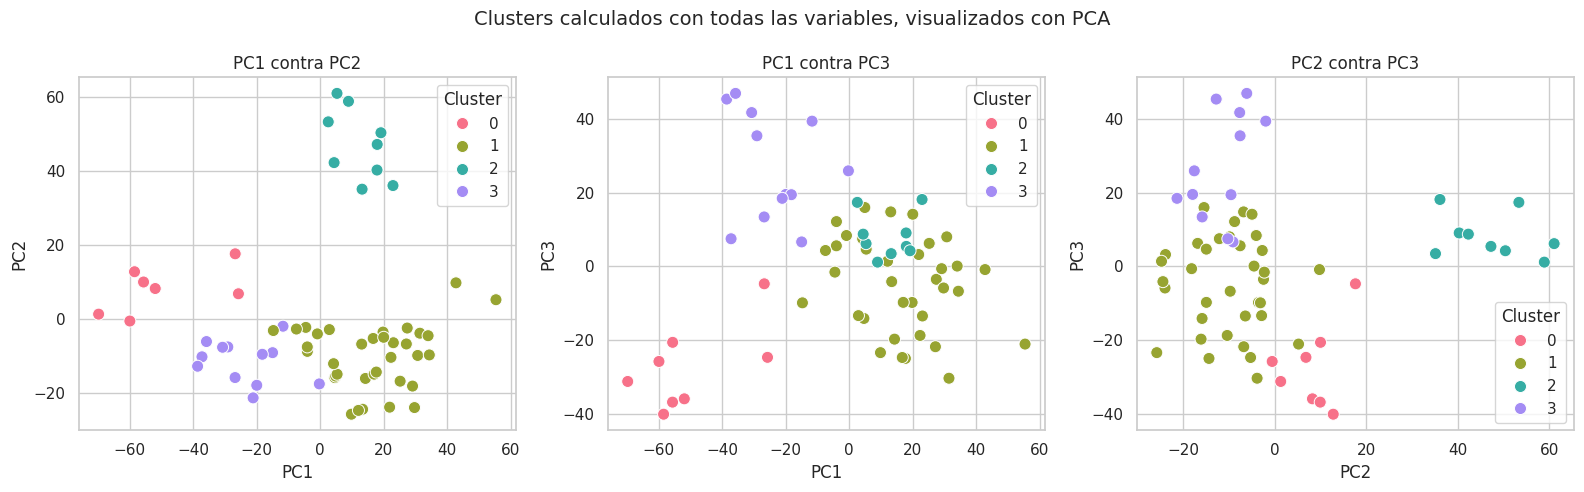

In [26]:
pares_pc = [
    ("PC1", "PC2"),
    ("PC1", "PC3"),
    ("PC2", "PC3")
]

paleta_nci = sns.color_palette("husl", n_colors=k_inicial)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (pc_x, pc_y) in zip(axes, pares_pc):

    sns.scatterplot(
        x=df_pca_nci[pc_x].to_numpy(),
        y=df_pca_nci[pc_y].to_numpy(),
        hue=clusters_nci_original,
        palette=paleta_nci,
        s=75,
        edgecolor="white",
        ax=ax
    )

    ax.set_title(f"{pc_x} contra {pc_y}")
    ax.set_xlabel(pc_x)
    ax.set_ylabel(pc_y)
    ax.legend(title="Cluster")

fig.suptitle(
    "Clusters calculados con todas las variables, visualizados con PCA",
    fontsize=14
)

plt.tight_layout()
plt.show()

Al visualizar los clusters con PCA, se observa una separación más clara que al utilizar pares de variables genéticas individuales. En PC1 contra PC2, el cluster 2, de color turquesa, se distingue por sus valores altos de PC2, mientras que el cluster 0, rosa, aparece principalmente hacia los valores más negativos de PC1.

En PC1 contra PC3, el componente PC3 permite distinguir mejor al cluster 3, morado, que presenta valores positivos, del cluster 0, cuyos valores son negativos. Por su parte, en PC2 contra PC3, el cluster 2 se ubica hacia la derecha y el cluster 0 hacia la parte inferior. El cluster 1, verde, ocupa una región más amplia y presenta cierta superposición con otros grupos.

Estos resultados muestran que los primeros tres componentes reflejan diferencias entre los clusters, aunque la separación no es perfecta. Los grupos siguen siendo los calculados con todas las variables originales estandarizadas, PCA únicamente permite visualizarlos en un espacio de menor dimensión.

### Paso 19. Análisis de la varianza explicada
Para decidir cuántos componentes se conservarán, se revisará la proporción de varianza explicada por cada uno y la varianza acumulada.

La varianza acumulada indica qué proporción de la variación total se conserva al utilizar los primeros componentes. En este tutorial se tomará 80 % como un criterio inicial, no como una regla obligatoria ni como garantía de obtener mejores clusters.

In [27]:
# Varianza explicada individual y acumulada
varianza_individual = pca_nci.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_individual)

# Seleccionar el mínimo número de componentes que alcanza el 80 %
umbral_varianza = 0.80

n_componentes_nci = int(
    np.searchsorted(varianza_acumulada, umbral_varianza) + 1
)

tabla_varianza = pd.DataFrame({
    "Componente": df_pca_nci.columns,
    "Varianza explicada (%)": varianza_individual * 100,
    "Varianza acumulada (%)": varianza_acumulada * 100
})

display(
    tabla_varianza.head(10).style
    .format({
        "Varianza explicada (%)": "{:.2f}",
        "Varianza acumulada (%)": "{:.2f}"
    })
    .hide(axis="index")
    .set_caption("Varianza explicada de los primeros 10 componentes")
)

print(
    f"Componentes necesarios para conservar al menos "
    f"el {umbral_varianza:.0%}: {n_componentes_nci}"
)

print(
    f"Varianza acumulada conservada: "
    f"{varianza_acumulada[n_componentes_nci - 1]:.2%}"
)

Componente,Varianza explicada (%),Varianza acumulada (%)
PC1,11.36,11.36
PC2,6.76,18.12
PC3,5.75,23.87
PC4,4.25,28.11
PC5,3.73,31.85
PC6,3.62,35.47
PC7,3.07,38.53
PC8,2.69,41.22
PC9,2.53,43.75
PC10,2.38,46.13


Componentes necesarios para conservar al menos el 80%: 32
Varianza acumulada conservada: 80.07%


Ahora se graficarán ambas medidas:

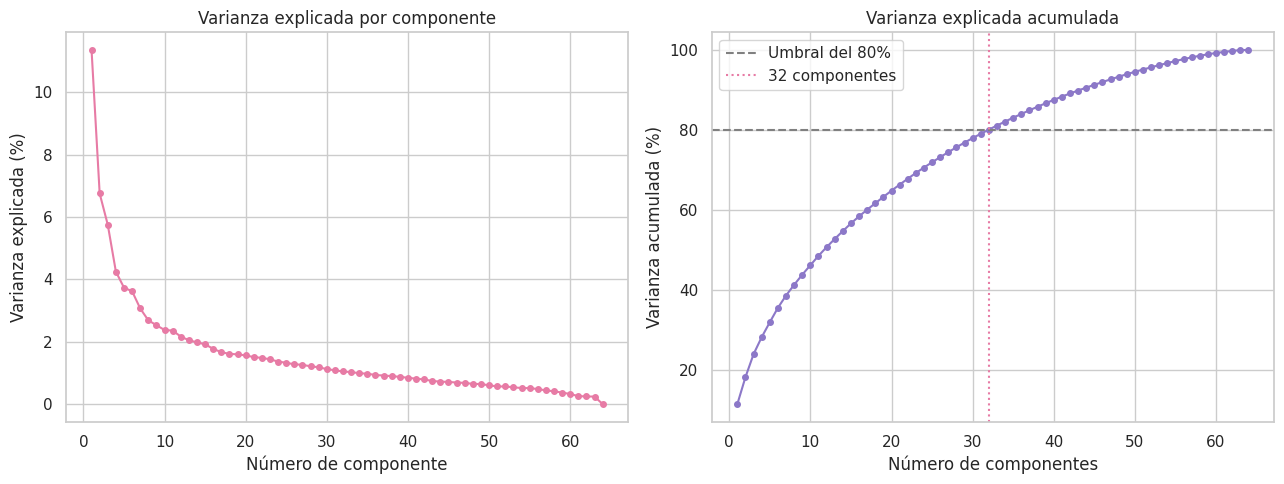

In [28]:
numeros_pc = np.arange(1, len(varianza_individual) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Varianza individual
axes[0].plot(
    numeros_pc,
    varianza_individual * 100,
    marker="o",
    markersize=4,
    color="#E77BA5"
)

axes[0].set_title("Varianza explicada por componente")
axes[0].set_xlabel("Número de componente")
axes[0].set_ylabel("Varianza explicada (%)")

# Varianza acumulada
axes[1].plot(
    numeros_pc,
    varianza_acumulada * 100,
    marker="o",
    markersize=4,
    color="#8C78C8"
)

axes[1].axhline(
    umbral_varianza * 100,
    color="gray",
    linestyle="--",
    label=f"Umbral del {umbral_varianza:.0%}"
)

axes[1].axvline(
    n_componentes_nci,
    color="#E77BA5",
    linestyle=":",
    label=f"{n_componentes_nci} componentes"
)

axes[1].set_title("Varianza explicada acumulada")
axes[1].set_xlabel("Número de componentes")
axes[1].set_ylabel("Varianza acumulada (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

La primera gráfica muestra que PC1 explica aproximadamente el 11 % de la variación total, seguido de PC2 con cerca del 7 %. Después, el aporte de cada componente disminuye gradualmente. Esto indica que la variación está distribuida entre numerosos componentes y no se concentra únicamente en los primeros dos o tres.

La gráfica de varianza acumulada muestra que se necesitan 32 componentes para conservar al menos el 80 % de la variación. Por ello, se utilizarán estos 32 componentes para aplicar K-means. Aunque las visualizaciones mostrarán solo dos componentes a la vez, el agrupamiento considerará los 32 seleccionados.

Esta elección permite reducir la cantidad de variables, dejando fuera aproximadamente el 20 % de la variación. Sin embargo, conservar el 80 % no garantiza por sí solo que los clusters sean mejores, sus resultados deberán revisarse posteriormente.

### Paso 20. Selección del número de clusters con PCA
Se conservarán los componentes necesarios para alcanzar el umbral y se probarán nuevamente tres, cuatro y cinco clusters.

Además de la inercia, se calculará el coeficiente de silueta, que considera qué tan cerca está cada observación de su propio grupo en comparación con los otros grupos. Un valor más alto sugiere grupos más compactos y separados bajo la distancia utilizada.

In [29]:
from sklearn.metrics import silhouette_score

# Conservar los componentes seleccionados
X_nci_pca = df_pca_nci.iloc[:, :n_componentes_nci].copy()

modelos_nci_pca = {}
resultados_nci_pca = []

for k_pca in [3, 4, 5]:

    modelo = KMeans(
        n_clusters=k_pca,
        n_init=30,
        random_state=42
    )

    asignaciones = modelo.fit_predict(X_nci_pca)

    silueta = silhouette_score(
        X_nci_pca,
        asignaciones,
        metric="euclidean"
    )

    modelos_nci_pca[k_pca] = modelo

    resultados_nci_pca.append({
        "Número de clusters": k_pca,
        "Inercia": modelo.inertia_,
        "Silueta": silueta
    })

tabla_resultados_pca = pd.DataFrame(resultados_nci_pca)

display(
    tabla_resultados_pca.style
    .format({
        "Inercia": "{:,.2f}",
        "Silueta": "{:.3f}"
    })
    .hide(axis="index")
    .set_caption("Comparación de K-means con los componentes seleccionados")
)

# Seleccionar la mayor silueta entre las alternativas probadas
fila_seleccionada = tabla_resultados_pca["Silueta"].idxmax()

k_seleccionado_pca = int(
    tabla_resultados_pca.loc[
        fila_seleccionada, "Número de clusters"
    ]
)

modelo_nci_pca = modelos_nci_pca[k_seleccionado_pca]
clusters_nci_pca = modelo_nci_pca.labels_

print(f"Número de clusters seleccionado: {k_seleccionado_pca}")

Número de clusters,Inercia,Silueta
3,"285,724.41",0.108
4,"265,281.31",0.121
5,"248,731.45",0.132


Número de clusters seleccionado: 5


Se selecciona la alternativa con mayor silueta entre los valores probados. Esta es una elección exploratoria que debe complementarse con las gráficas y la interpretación de los grupos. No demuestra que exista un número definitivo de clusters ni que estos correspondan directamente a tipos de cáncer.

La inercia de esta tabla no debe compararse directamente con la del modelo anterior, porque ahora las distancias se calculan en un espacio con menos dimensiones.

### Paso 21. Visualización de K-means con PCA
Ahora se mostrarán los clusters obtenidos al entrenar K-means con los componentes seleccionados.

Las gráficas mostrarán únicamente dos componentes a la vez, aunque el modelo haya utilizado más.

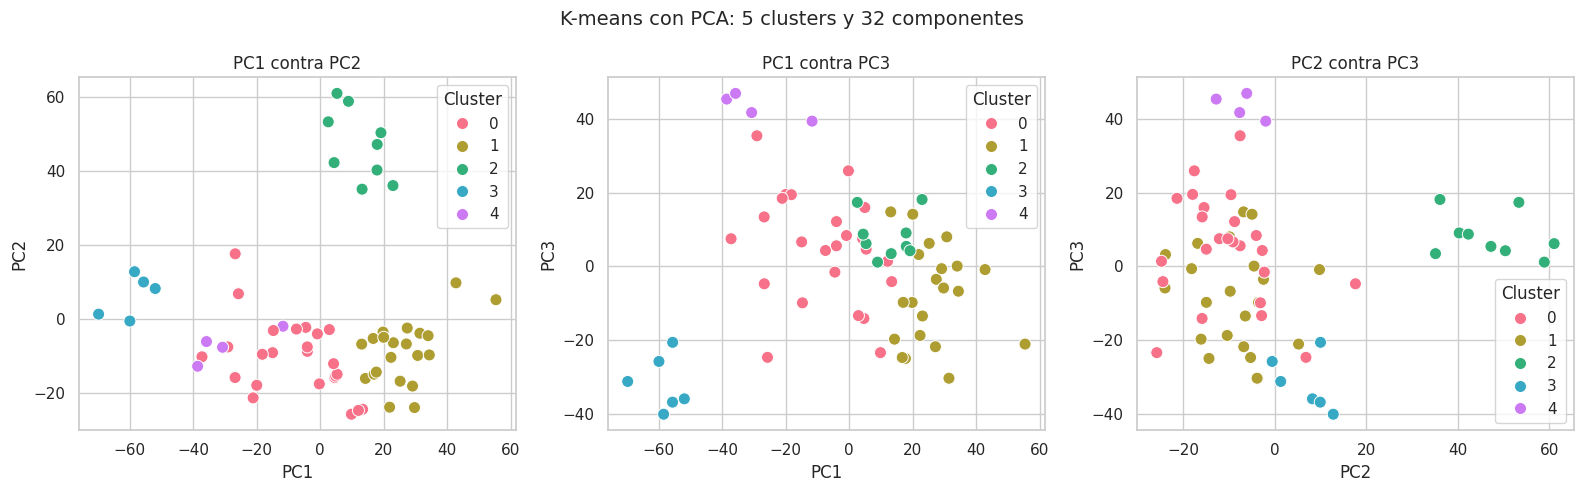

In [30]:
paleta_pca = sns.color_palette(
    "husl",
    n_colors=k_seleccionado_pca
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (pc_x, pc_y) in zip(axes, pares_pc):

    sns.scatterplot(
        x=df_pca_nci[pc_x].to_numpy(),
        y=df_pca_nci[pc_y].to_numpy(),
        hue=clusters_nci_pca,
        palette=paleta_pca,
        s=75,
        edgecolor="white",
        ax=ax
    )

    ax.set_title(f"{pc_x} contra {pc_y}")
    ax.set_xlabel(pc_x)
    ax.set_ylabel(pc_y)
    ax.legend(title="Cluster")

fig.suptitle(
    f"K-means con PCA: {k_seleccionado_pca} clusters "
    f"y {n_componentes_nci} componentes",
    fontsize=14
)

plt.tight_layout()
plt.show()

Al aplicar K-means con 32 componentes principales, se obtuvieron cinco clusters. En la gráfica de PC1 contra PC2, el cluster 2, verde, se distingue por sus valores altos de PC2, mientras que el cluster 3, azul, se ubica hacia los valores más negativos de PC1. El cluster 1, amarillo, aparece principalmente a la derecha y el cluster 0, rosa, ocupa una región más amplia en la parte central e izquierda.

En PC1 contra PC3, el cluster 4, morado, se distingue por sus valores altos de PC3, mientras que el cluster 3 presenta valores negativos. La gráfica de PC2 contra PC3 también permite reconocer estos grupos, aunque existe superposición entre los clusters 0 y 1.

En conjunto, los primeros tres componentes permiten visualizar varias diferencias entre los cinco grupos, pero la separación no es completa. El modelo utilizó los 32 componentes seleccionados, por lo que algunas diferencias entre clusters pueden encontrarse en dimensiones que no aparecen en estas gráficas.

### Paso 22. Comparación entre clases y clusters
Finalmente, se construirá una tabla para conocer cuántas observaciones de cada etiqueta de cáncer quedaron en cada cluster.

Las etiquetas se incorporan únicamente para interpretar el resultado; no participaron en el ajuste de PCA ni en el entrenamiento de K-means.

Cluster,0,1,2,3,4
Tipo de cáncer,,,,,
BREAST,0,3,2,0,2
CNS,0,5,0,0,0
COLON,7,0,0,0,0
K562A-repro,0,0,0,1,0
K562B-repro,0,0,0,1,0
LEUKEMIA,2,0,0,4,0
MCF7A-repro,0,0,0,0,1
MCF7D-repro,0,0,0,0,1
MELANOMA,1,0,7,0,0


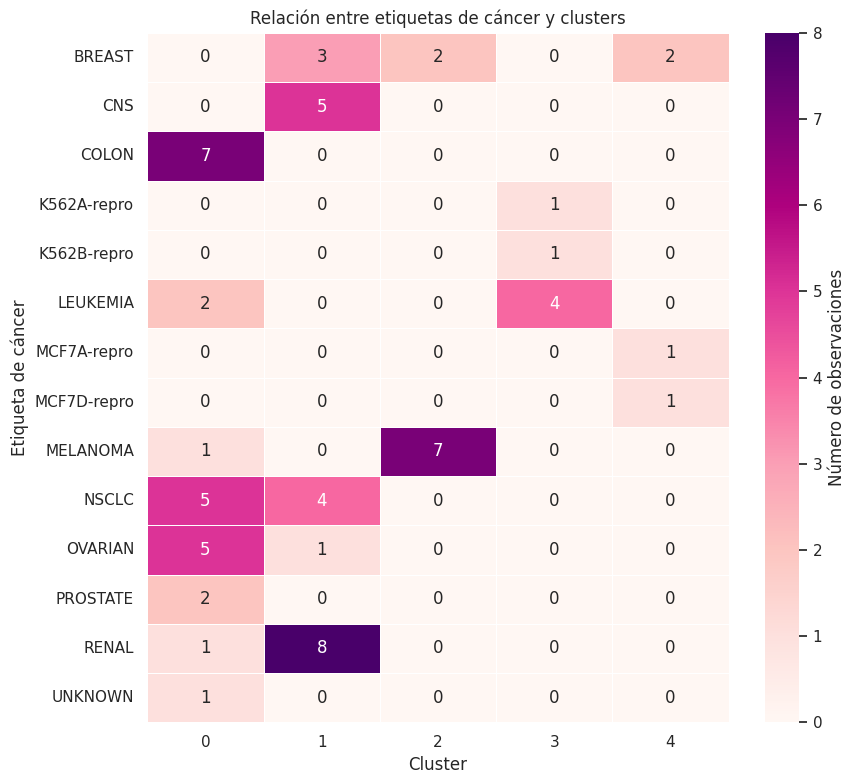

In [31]:
# Construir una tabla con las etiquetas y los clusters
asignaciones_nci = pd.DataFrame({
    "Tipo de cáncer": etiquetas_cancer.to_numpy(),
    "Cluster": clusters_nci_pca
})

tabla_clases_clusters = pd.crosstab(
    asignaciones_nci["Tipo de cáncer"],
    asignaciones_nci["Cluster"]
)

display(
    tabla_clases_clusters.style
    .set_caption("Distribución de las etiquetas de cáncer por cluster")
)

# Visualizar las cantidades
plt.figure(figsize=(9, 8))

sns.heatmap(
    tabla_clases_clusters,
    annot=True,
    fmt="d",
    cmap="RdPu",
    linewidths=0.5,
    cbar_kws={"label": "Número de observaciones"}
)

plt.title("Relación entre etiquetas de cáncer y clusters")
plt.xlabel("Cluster")
plt.ylabel("Etiqueta de cáncer")
plt.tight_layout()
plt.show()

El mapa de calor muestra que algunas etiquetas se concentran en un mismo cluster. Las 7 observaciones de COLON quedaron en el cluster 0 y las 5 de CNS en el cluster 1. También se observa una concentración importante de RENAL, con 8 de sus 9 observaciones en el cluster 1, y de MELANOMA, con 7 de sus 8 observaciones en el cluster 2.

Otras categorías se distribuyen entre varios grupos. Por ejemplo, BREAST aparece en los clusters 1, 2 y 4, mientras que NSCLC se divide entre los clusters 0 y 1. Además, un mismo cluster reúne distintas etiquetas: el cluster 0 incluye observaciones de colon, ovario, próstata y otras categorías.

Estos resultados indican que el agrupamiento refleja similitudes de expresión genética que coinciden parcialmente con las etiquetas de cáncer. Sin embargo, los clusters no equivalen directamente a tipos de cáncer, ya que pueden reunir distintas categorías o separar observaciones de una misma etiqueta.

### Paso 23. Selección de dos clusters
Se compararán los clusters 1 y 2 del modelo con PCA. En los resultados anteriores, el cluster 1 concentró principalmente las observaciones RENAL y CNS, mientras que el cluster 2 reunió la mayoría de las observaciones MELANOMA.

Esta comparación permitirá explorar qué variables genéticas presentan las mayores diferencias promedio entre ambos grupos.

In [32]:
# Clusters que se compararán
clusters_comparar = [1, 2]

# Identificar las observaciones de ambos clusters
mascara_clusters = np.isin(
    clusters_nci_pca,
    clusters_comparar
)

# Recuperar sus mediciones genéticas originales
X_dos_clusters = X_nci.loc[mascara_clusters].copy()

# Guardar el cluster correspondiente a cada observación
grupos_dos_clusters = pd.Series(
    clusters_nci_pca[mascara_clusters],
    index=X_dos_clusters.index,
    name="Cluster"
)

print("Observaciones seleccionadas por cluster:")
display(
    grupos_dos_clusters.value_counts()
    .sort_index()
    .rename("Número de observaciones")
    .to_frame()
)

Observaciones seleccionadas por cluster:


,Número de observaciones
Cluster,
1,21
2,9


Se seleccionaron 30 líneas celulares: 21 del cluster 1 y 9 del cluster 2. Se conservaron las asignaciones obtenidas mediante K-means con PCA y se recuperaron sus mediciones genéticas originales para comparar la expresión promedio de cada variable entre ambos grupos.

Como los clusters tienen tamaños diferentes, se compararán sus promedios, en lugar de sus sumas, para evitar que el grupo con más observaciones presente valores mayores únicamente por su tamaño.

### Paso 24. Cálculo de las diferencias de expresión promedio
Primero se calculará la expresión promedio de cada variable genética dentro de cada cluster. Después se obtendrá la diferencia absoluta entre ambos promedios.

Se seleccionarán las 40 variables con mayor diferencia, dentro del intervalo de 30 a 50 solicitado en la presentación.

In [33]:
# Promedio de cada variable genética por cluster
promedios_genes = X_dos_clusters.groupby(
    grupos_dos_clusters
).mean()

# Diferencia absoluta de los promedios
diferencias_genes = (
    promedios_genes.loc[clusters_comparar[0]]
    - promedios_genes.loc[clusters_comparar[1]]
).abs()

# Seleccionar las 40 variables con mayor diferencia
n_genes_heatmap = 40

genes_seleccionados = (
    diferencias_genes
    .sort_values(ascending=False)
    .head(n_genes_heatmap)
    .index
)

# Tabla de las variables seleccionadas
tabla_diferencias = pd.DataFrame({
    "Variable genética": genes_seleccionados,
    f"Promedio cluster {clusters_comparar[0]}":
        promedios_genes.loc[
            clusters_comparar[0], genes_seleccionados
        ].to_numpy(),
    f"Promedio cluster {clusters_comparar[1]}":
        promedios_genes.loc[
            clusters_comparar[1], genes_seleccionados
        ].to_numpy(),
    "Diferencia absoluta":
        diferencias_genes.loc[genes_seleccionados].to_numpy()
})

display(
    tabla_diferencias.head(10).style
    .format(precision=3)
    .hide(axis="index")
    .set_caption(
        "Primeras 10 variables con mayor diferencia entre clusters"
    )
)

Variable genética,Promedio cluster 1,Promedio cluster 2,Diferencia absoluta
6414,2.989,-1.611,4.600
6392,2.987,-1.403,4.390
5585,1.872,-2.379,4.251
4307,-0.025,4.207,4.231
4326,0.155,4.341,4.186
4319,0.045,4.129,4.083
6355,0.608,-3.317,3.925
6415,2.719,-1.198,3.917
4305,0.247,4.062,3.815
5842,1.111,-2.607,3.718


La variable 6414 presenta la mayor diferencia absoluta entre los clusters, con un valor de 4.600: su promedio es 2.989 en el cluster 1 y −1.611 en el cluster 2. Le siguen las variables 6392 y 5585, con diferencias de 4.390 y 4.251, respectivamente.

Las diferencias aparecen en ambas direcciones. Por ejemplo, la variable 6414 tiene un promedio mayor en el cluster 1, mientras que la 4307 presenta un promedio mayor en el cluster 2: 4.207, frente a −0.025 en el cluster 1. Esto muestra que los grupos tienen distintos patrones de expresión en las variables seleccionadas.

Sin embargo, estas diferencias son descriptivas, ya que no demuestran por sí solas significancia estadística ni importancia biológica. Los números identifican las variables dentro de la base; para relacionarlas con genes específicos sería necesario consultar su anotación.

### Paso 25. Estandarización de las variables seleccionadas
Para visualizar juntas las 40 variables, se estandarizarán sus valores utilizando todas las observaciones seleccionadas de ambos clusters. Después se calculará el promedio estandarizado de cada variable por cluster.

Esto permitirá comparar patrones relativos sin que las diferencias de escala dominen los colores del heatmap.

In [37]:
# Seleccionar las 40 variables
X_genes_seleccionados = X_dos_clusters.loc[
    :, genes_seleccionados
]

# Estandarizar usando las observaciones de ambos clusters
escalador_heatmap = StandardScaler()

X_genes_heatmap_std = pd.DataFrame(
    escalador_heatmap.fit_transform(X_genes_seleccionados),
    index=X_genes_seleccionados.index,
    columns=X_genes_seleccionados.columns
)

# Promedio estandarizado de cada variable por cluster
promedios_heatmap = X_genes_heatmap_std.groupby(
    grupos_dos_clusters
).mean()

# Transponer: variables en filas y clusters en columnas
datos_heatmap = promedios_heatmap.T

### Paso 26. Visualización del heatmap
En el mapa de calor, cada fila representará una variable genética y cada columna uno de los clusters comparados. Los colores mostrarán su expresión promedio estandarizada.

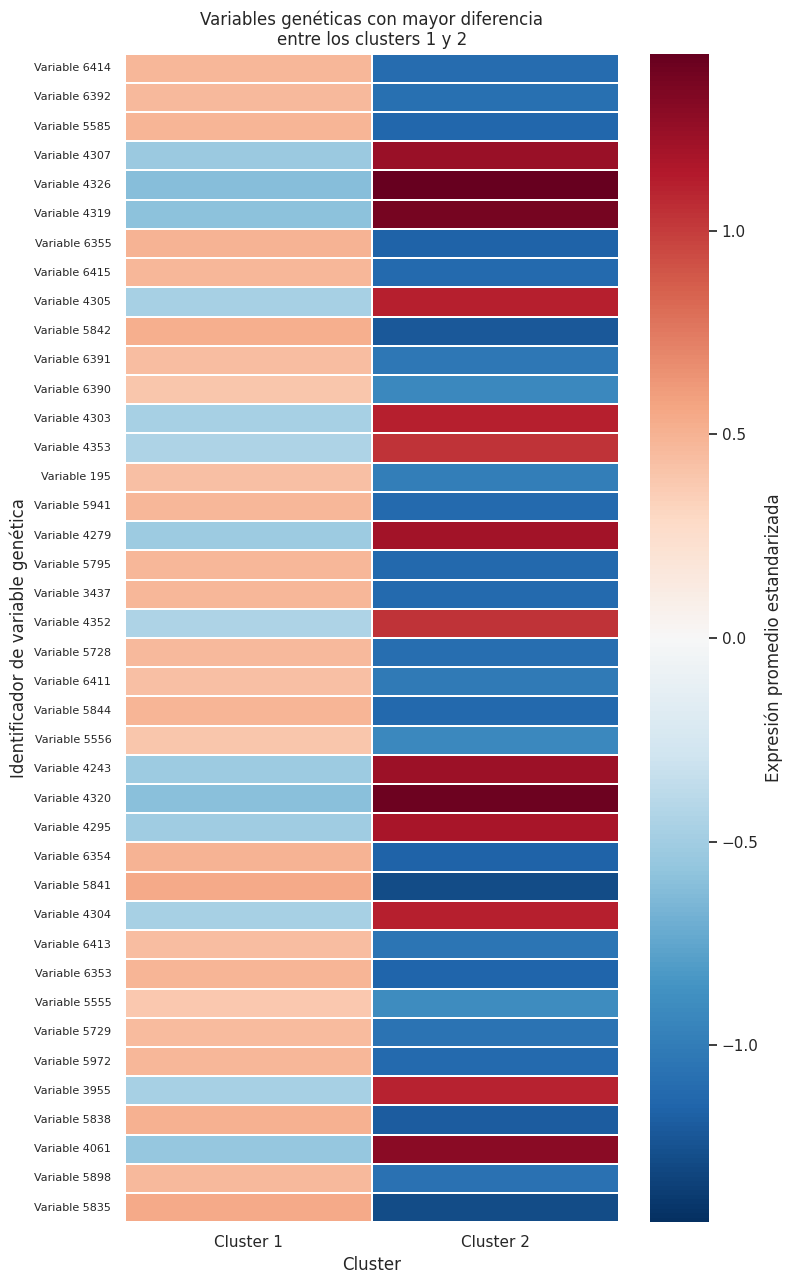

In [38]:
# Etiquetas para identificar las variables
# Se conservan los identificadores disponibles en la base
etiquetas_genes = [
    f"Variable {gen}"
    for gen in datos_heatmap.index
]

# Escala simétrica alrededor de cero
limite_color = np.abs(datos_heatmap.to_numpy()).max()

plt.figure(figsize=(8, 13))

sns.heatmap(
    datos_heatmap,
    cmap="RdBu_r",
    center=0,
    vmin=-limite_color,
    vmax=limite_color,
    yticklabels=etiquetas_genes,
    xticklabels=[
        f"Cluster {cluster}"
        for cluster in datos_heatmap.columns
    ],
    linewidths=0.3,
    cbar_kws={
        "label": "Expresión promedio estandarizada"
    }
)

plt.title(
    "Variables genéticas con mayor diferencia\n"
    "entre los clusters 1 y 2"
)
plt.xlabel("Cluster")
plt.ylabel("Identificador de variable genética")
plt.xticks(rotation=0)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

El mapa de calor muestra diferencias en la expresión promedio de las 40 variables seleccionadas entre los clusters 1 y 2. Por ejemplo, las variables 6414, 6392 y 5585 presentan valores por encima del promedio conjunto en el cluster 1 y por debajo en el cluster 2. En cambio, las variables 4307, 4326 y 4319 muestran el patrón contrario.

Los colores del cluster 2 son generalmente más intensos. Esto se relaciona con su menor tamaño: contiene 9 observaciones, frente a las 21 del cluster 1, por lo que el promedio conjunto está más cerca del grupo más grande. No significa que el cluster 2 sea más importante.

Estos contrastes permiten describir diferencias entre los grupos, pero eran esperables porque se seleccionaron las variables con mayor diferencia promedio. Por lo tanto, el análisis es exploratorio y no demuestra que estas variables sean marcadores de cáncer. Los colores opuestos tampoco indican, por sí solos, una relación inversa entre los genes.

## Parte 3. Hierarchical clustering

### Paso 27. Preparación para hierarchical clustering
El clustering jerárquico comienza considerando cada observación como un grupo independiente. Después une progresivamente los grupos más similares hasta reunir todas las observaciones.

El resultado se representa mediante un dendrograma, que permite observar el orden de las uniones y la disimilitud a la que ocurren. A diferencia de K-means, no es necesario fijar el número de clusters para construir el árbol.

Se reutilizará X_nci_pca, que contiene los componentes seleccionados de todas las líneas celulares, no solamente las observaciones de los dos clusters comparados en el heatmap.

In [39]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Recuperar los componentes de todas las líneas celulares
X_jerarquico = X_nci_pca.copy()

# Etiquetas para identificar cada observación en el dendrograma
etiquetas_dendrograma = [
    f"{i + 1}: {etiqueta}"
    for i, etiqueta in enumerate(etiquetas_cancer.to_numpy())
]

print(f"Líneas celulares: {X_jerarquico.shape[0]}")
print(f"Componentes utilizados: {X_jerarquico.shape[1]}")

Líneas celulares: 64
Componentes utilizados: 32


Las etiquetas de cáncer se mostrarán para facilitar la interpretación, pero no se utilizarán para calcular las uniones.

### Paso 28. Hierarchical clustering con complete y distancia euclidiana
Primero se utilizará el método de enlace complete y la distancia euclidiana.

La distancia euclidiana mide la separación entre dos observaciones en el espacio de los componentes. El enlace complete define la distancia entre dos grupos como la mayor distancia entre un punto de un grupo y un punto del otro.

In [40]:
# Construir la jerarquía
Z_complete_euclidean = linkage(
    X_jerarquico.to_numpy(),
    method="complete",
    metric="euclidean"
)

print("Proceso de agrupamiento completado.")

Proceso de agrupamiento completado.


### Paso 29. Dendograma monocromático

Se graficará el árbol con todas sus ramas del mismo color para observar su estructura sin establecer todavía una división en clusters.

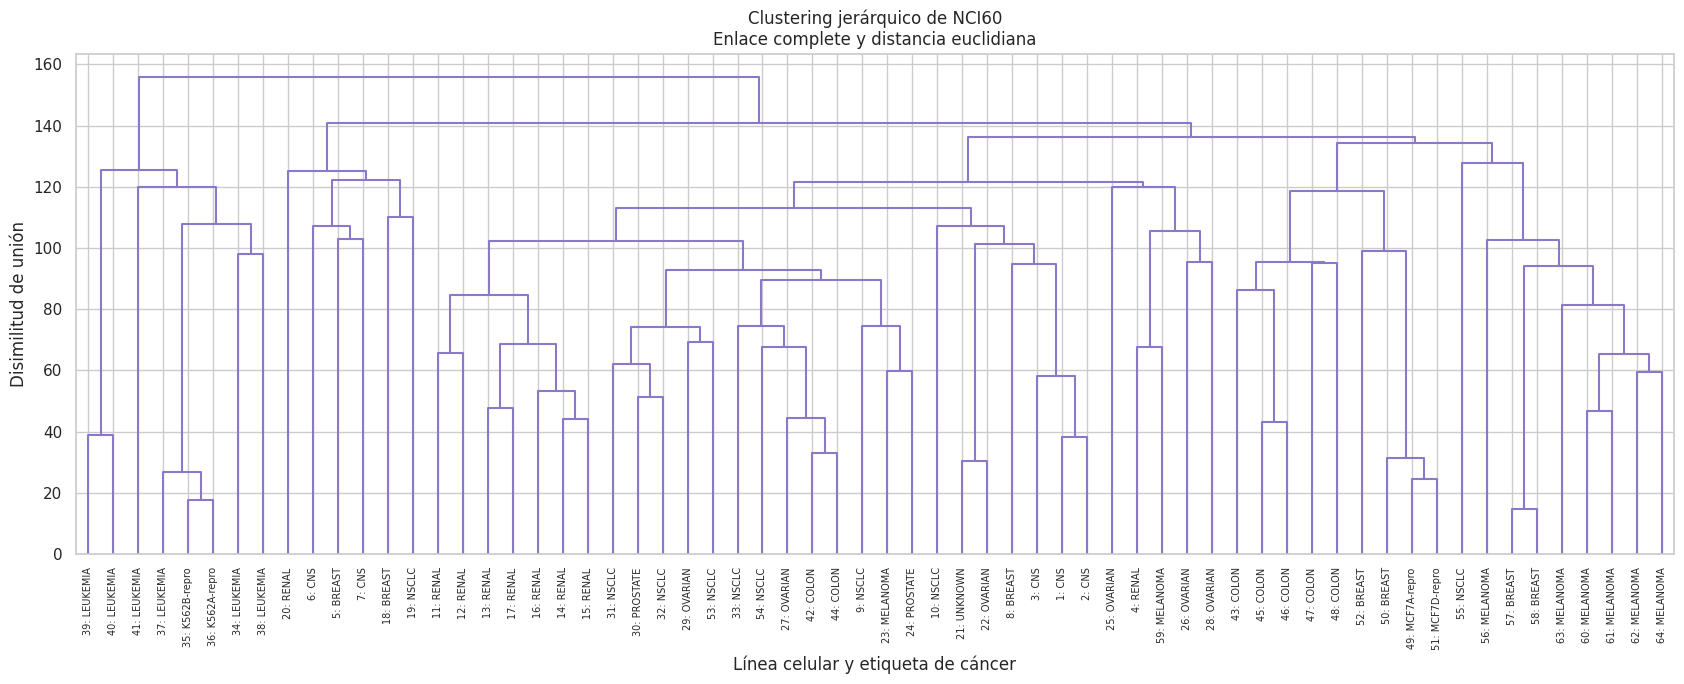

In [41]:
plt.figure(figsize=(17, 7))

dendrogram(
    Z_complete_euclidean,
    labels=etiquetas_dendrograma,
    leaf_rotation=90,
    leaf_font_size=7,
    link_color_func=lambda _: "#8C78C8"
)

plt.title(
    "Clustering jerárquico de NCI60\n"
    "Enlace complete y distancia euclidiana"
)
plt.xlabel("Línea celular y etiqueta de cáncer")
plt.ylabel("Disimilitud de unión")
plt.tight_layout()
plt.show()

El dendrograma muestra que algunas líneas celulares con la misma etiqueta se unen a alturas bajas, lo que indica similitud en los componentes utilizados. Por ejemplo, las observaciones K562A-repro y K562B-repro se unen cerca de una disimilitud de 18, mientras que varias observaciones de MELANOMA, ubicadas a la derecha, forman pequeños grupos antes de integrarse a ramas mayores.

También aparecen ramas con distintas etiquetas de cáncer. Esto indica que el agrupamiento refleja similitudes en la expresión genética que no coinciden completamente con las categorías originales.

La última unión ocurre aproximadamente a una disimilitud de 156. Un corte horizontal alrededor de 150 produciría dos clusters, mientras que uno cercano a 138 generaría tres. Estas son alternativas para explorar la estructura de los datos, no demuestran que exista una única cantidad correcta de grupos.

### Paso 30. Cortes del dendrograma en 2, 3 y 4 clusters
El dendrograma ya contiene una jerarquía completa. Para obtener grupos concretos, se establece una altura de corte: las ramas que quedan conectadas por debajo de esa altura forman un mismo cluster.

Se calculará una altura entre las uniones correspondientes para obtener cada cantidad de grupos. No se vuelve a entrenar el modelo, únicamente se corta el mismo árbol a distintas alturas.

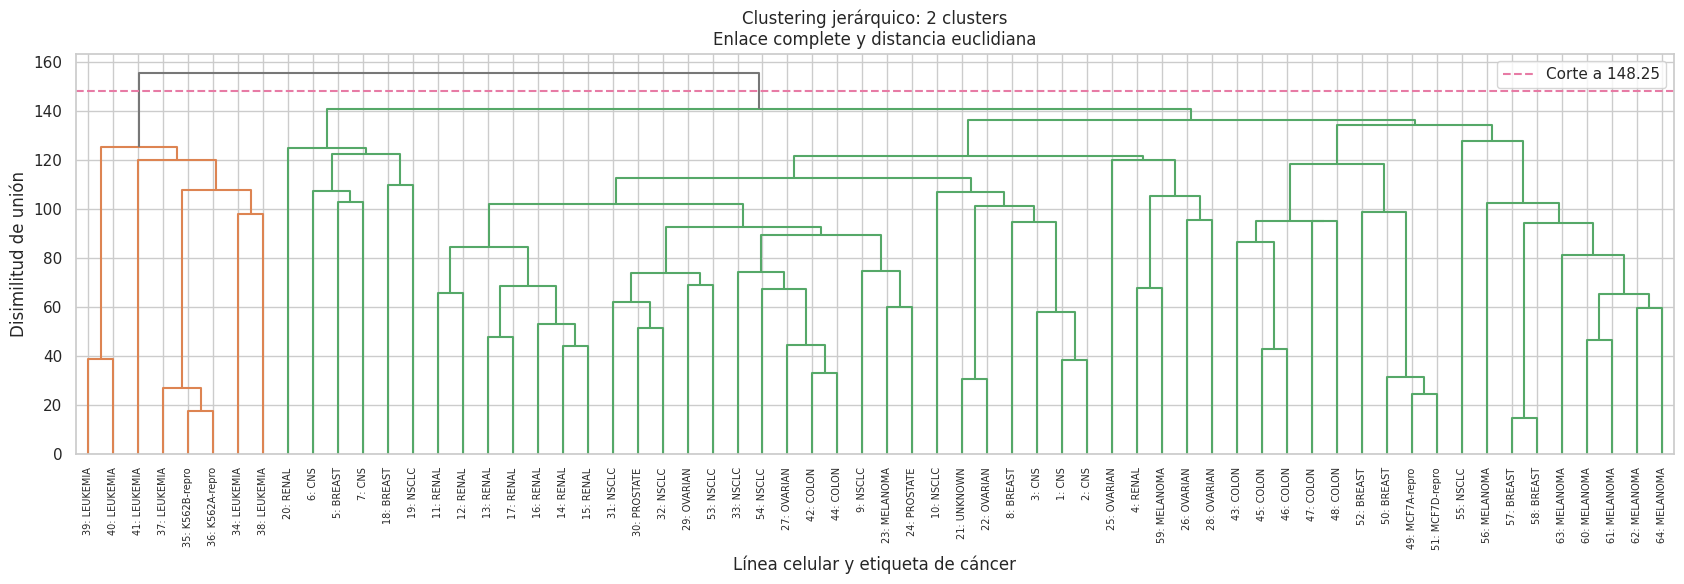

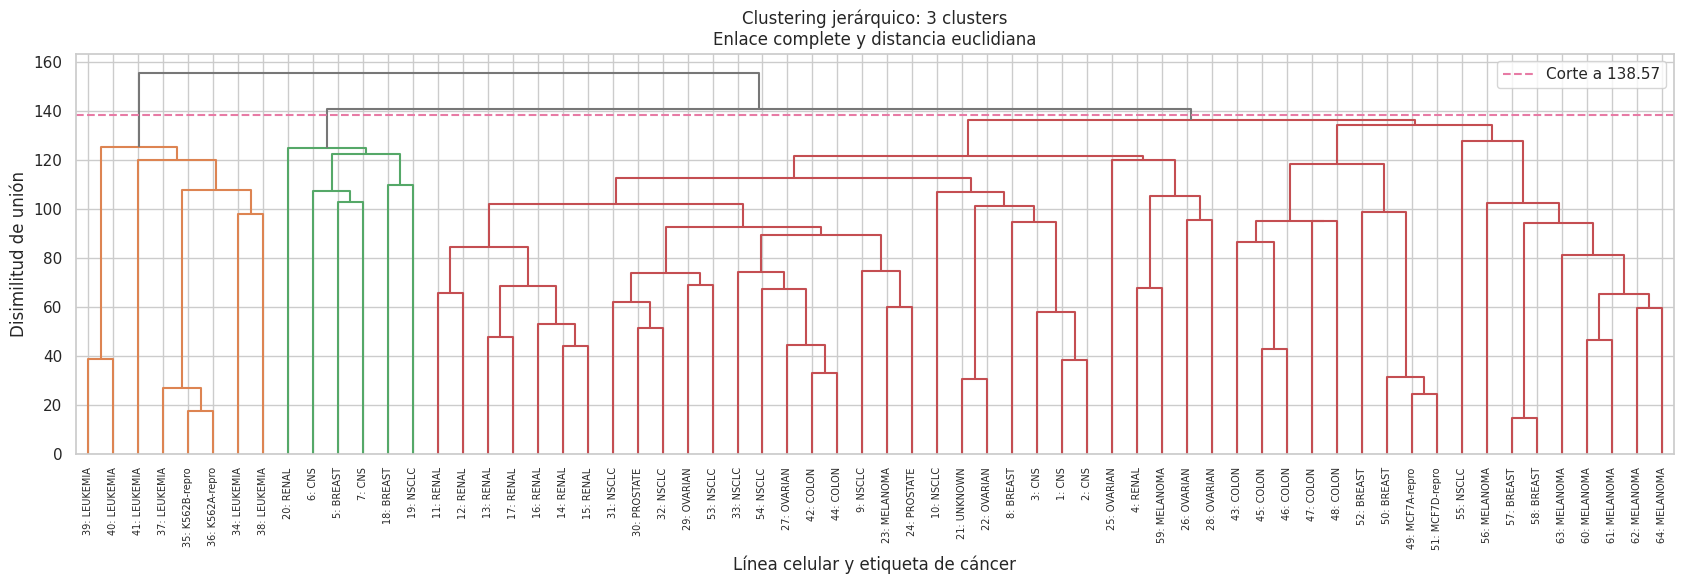

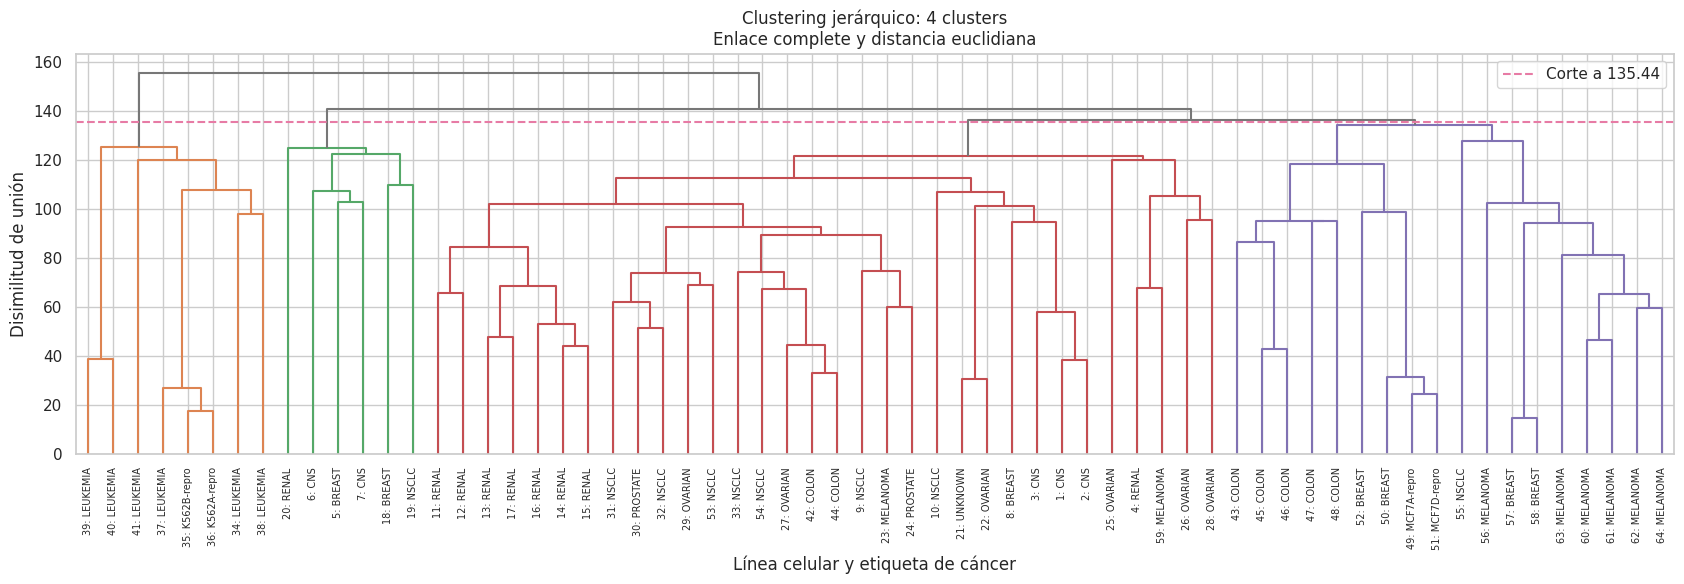

In [42]:
from scipy.cluster.hierarchy import fcluster

# Guardar las asignaciones y alturas de cada corte
clusters_por_corte = {}
alturas_corte = {}

for numero_clusters in [2, 3, 4]:

    # Alturas entre las que se puede cortar para obtener k grupos
    altura_inferior = Z_complete_euclidean[-numero_clusters, 2]
    altura_superior = Z_complete_euclidean[-numero_clusters + 1, 2]

    if altura_inferior == altura_superior:
        raise ValueError(
            f"No existe una altura de corte que produzca exactamente "
            f"{numero_clusters} grupos debido a un empate entre uniones."
        )

    altura = (altura_inferior + altura_superior) / 2

    asignaciones = fcluster(
        Z_complete_euclidean,
        t=altura,
        criterion="distance"
    )

    alturas_corte[numero_clusters] = altura
    clusters_por_corte[numero_clusters] = asignaciones

    # Graficar el árbol con el corte correspondiente
    plt.figure(figsize=(17, 6))

    dendrogram(
        Z_complete_euclidean,
        labels=etiquetas_dendrograma,
        leaf_rotation=90,
        leaf_font_size=7,
        color_threshold=altura,
        above_threshold_color="#777777"
    )

    plt.axhline(
        altura,
        color="#E77BA5",
        linestyle="--",
        label=f"Corte a {altura:.2f}"
    )

    plt.title(
        f"Clustering jerárquico: {numero_clusters} clusters\n"
        "Enlace complete y distancia euclidiana"
    )

    plt.xlabel("Línea celular y etiqueta de cáncer")
    plt.ylabel("Disimilitud de unión")
    plt.legend()
    plt.tight_layout()
    plt.show()

Al cortar el dendrograma a una altura de 138.57, se obtienen tres clusters. El grupo naranja reúne las observaciones de LEUKEMIA y las etiquetas K562A-repro y K562B-repro. El grupo verde contiene algunas líneas celulares de RENAL, CNS, BREAST y NSCLC, mientras que el grupo rojo reúne la mayor parte de las observaciones y presenta etiquetas variadas.

Este resultado muestra una separación clara de las líneas celulares de leucemia respecto al resto, pero los otros grupos no corresponden a un único tipo de cáncer.

Las uniones grises quedan por encima del corte y conectan los tres clusters a mayores niveles de disimilitud. Si se baja la línea de corte, alguna de estas ramas se dividirá en subgrupos; si se eleva, los grupos se unirán. Así se observa la estructura anidada del clustering jerárquico.

### Paso 31. Cantidad de observaciones por cluster
Se revisará cómo se distribuyen las líneas celulares en cada corte.

In [43]:
resumen_cortes = []

for numero_clusters, asignaciones in clusters_por_corte.items():

    conteos = pd.Series(asignaciones).value_counts().sort_index()

    for cluster, cantidad in conteos.items():
        resumen_cortes.append({
            "Número de clusters del corte": numero_clusters,
            "Cluster": cluster,
            "Número de observaciones": cantidad,
            "Altura de corte": alturas_corte[numero_clusters]
        })

tabla_cortes = pd.DataFrame(resumen_cortes)

display(
    tabla_cortes.style
    .format({"Altura de corte": "{:.2f}"})
    .hide(axis="index")
    .set_caption("Distribución de observaciones según el corte del dendrograma")
)

Número de clusters del corte,Cluster,Número de observaciones,Altura de corte
2,1,8,148.25
2,2,56,148.25
3,1,8,138.57
3,2,6,138.57
3,3,50,138.57
4,1,8,135.44
4,2,6,135.44
4,3,32,135.44
4,4,18,135.44


La tabla muestra que, al cortar a una altura de 148.25, se obtienen dos clusters de 8 y 56 observaciones. Al bajar el corte a 138.57, el grupo de 56 se divide en dos, de 6 y 50 observaciones, mientras que el de 8 permanece intacto.

Al disminuir la altura a 135.44, se obtienen cuatro clusters de 8, 6, 32 y 18 observaciones. En este caso, el grupo de 50 se divide en dos, mientras que los grupos de 8 y 6 se conservan.

### Paso 32. Enlace complete con distancia de correlación

Ahora se conservará el enlace complete, pero se cambiará la distancia euclidiana por la distancia de correlación.

En este caso, la correlación se calculará entre los perfiles de puntuaciones en los 32 componentes, porque seguimos utilizando X_jerarquico. Su interpretación corresponde a ese espacio reducido.

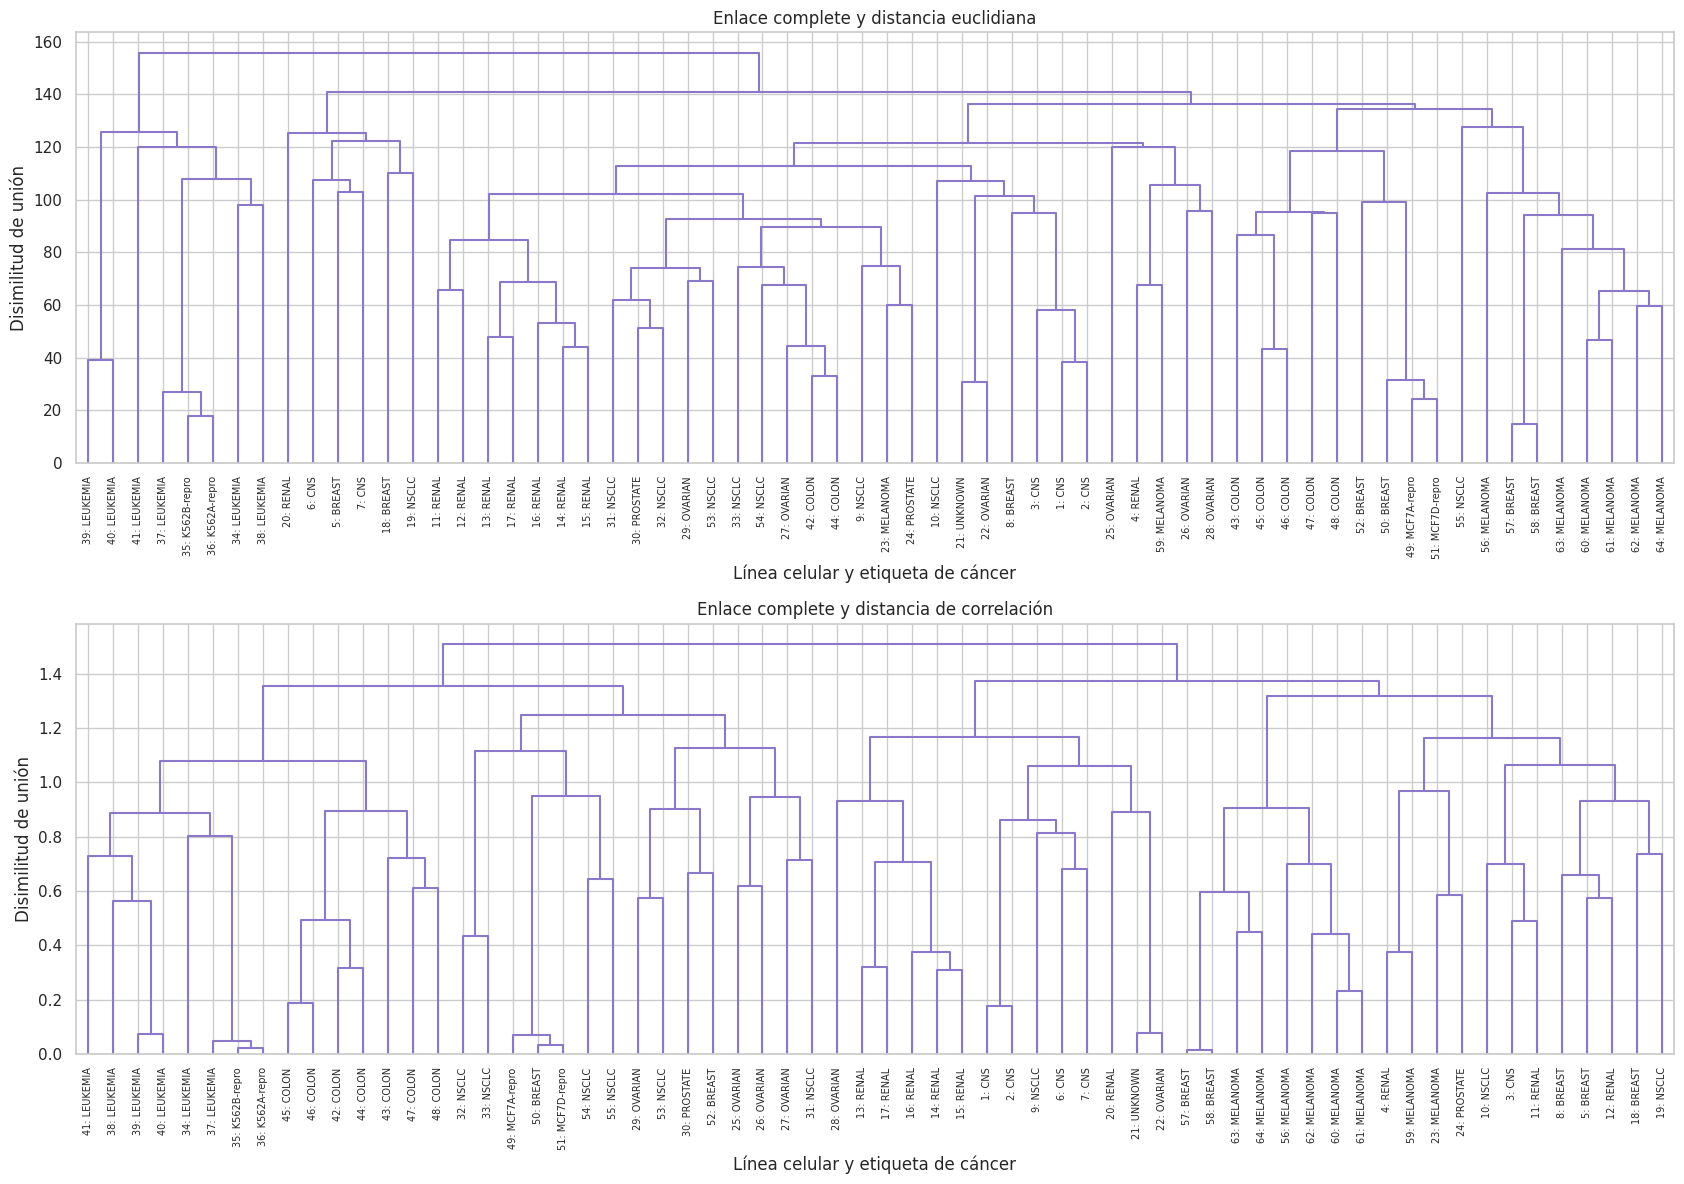

In [44]:
# Construir una nueva jerarquía con distancia de correlación
Z_complete_correlation = linkage(
    X_jerarquico.to_numpy(),
    method="complete",
    metric="correlation"
)

# Mostrar ambos dendrogramas para compararlos
fig, axes = plt.subplots(2, 1, figsize=(17, 12))

configuraciones = [
    (
        Z_complete_euclidean,
        "Enlace complete y distancia euclidiana"
    ),
    (
        Z_complete_correlation,
        "Enlace complete y distancia de correlación"
    )
]

for ax, (matriz_enlaces, titulo) in zip(axes, configuraciones):

    dendrogram(
        matriz_enlaces,
        labels=etiquetas_dendrograma,
        leaf_rotation=90,
        leaf_font_size=7,
        link_color_func=lambda _: "#8C78C8",
        ax=ax
    )

    ax.set_title(titulo)
    ax.set_xlabel("Línea celular y etiqueta de cáncer")
    ax.set_ylabel("Disimilitud de unión")

plt.tight_layout()
plt.show()

Al cambiar la distancia euclidiana por la de correlación, se modifica la estructura del dendrograma. Con la distancia euclidiana, las observaciones de LEUKEMIA y las etiquetas K562-repro forman una rama que se une al resto en la última unión. Con correlación, también permanecen agrupadas, pero esa rama se integra antes con otras observaciones.

Algunas agrupaciones se conservan, como los pares K562A-repro y K562B-repro, MCF7A-repro y MCF7D-repro, y varias líneas celulares de MELANOMA. Esto muestra que ciertas similitudes se mantienen con ambas medidas, aunque las agrupaciones más amplias cambian.

La distancia euclidiana considera la separación entre las puntuaciones de los componentes, mientras que la correlación compara la forma de esos perfiles. Las alturas no deben compararse directamente, porque están expresadas en medidas diferentes, una altura menor no significa un mejor agrupamiento.

### Paso 33. Enlace average con distancia euclidiana
Finalmente, se utilizará el enlace average con distancia euclidiana.

Mientras que complete utiliza la mayor distancia entre puntos de dos grupos, average utiliza el promedio de todas las distancias entre puntos de ambos grupos.

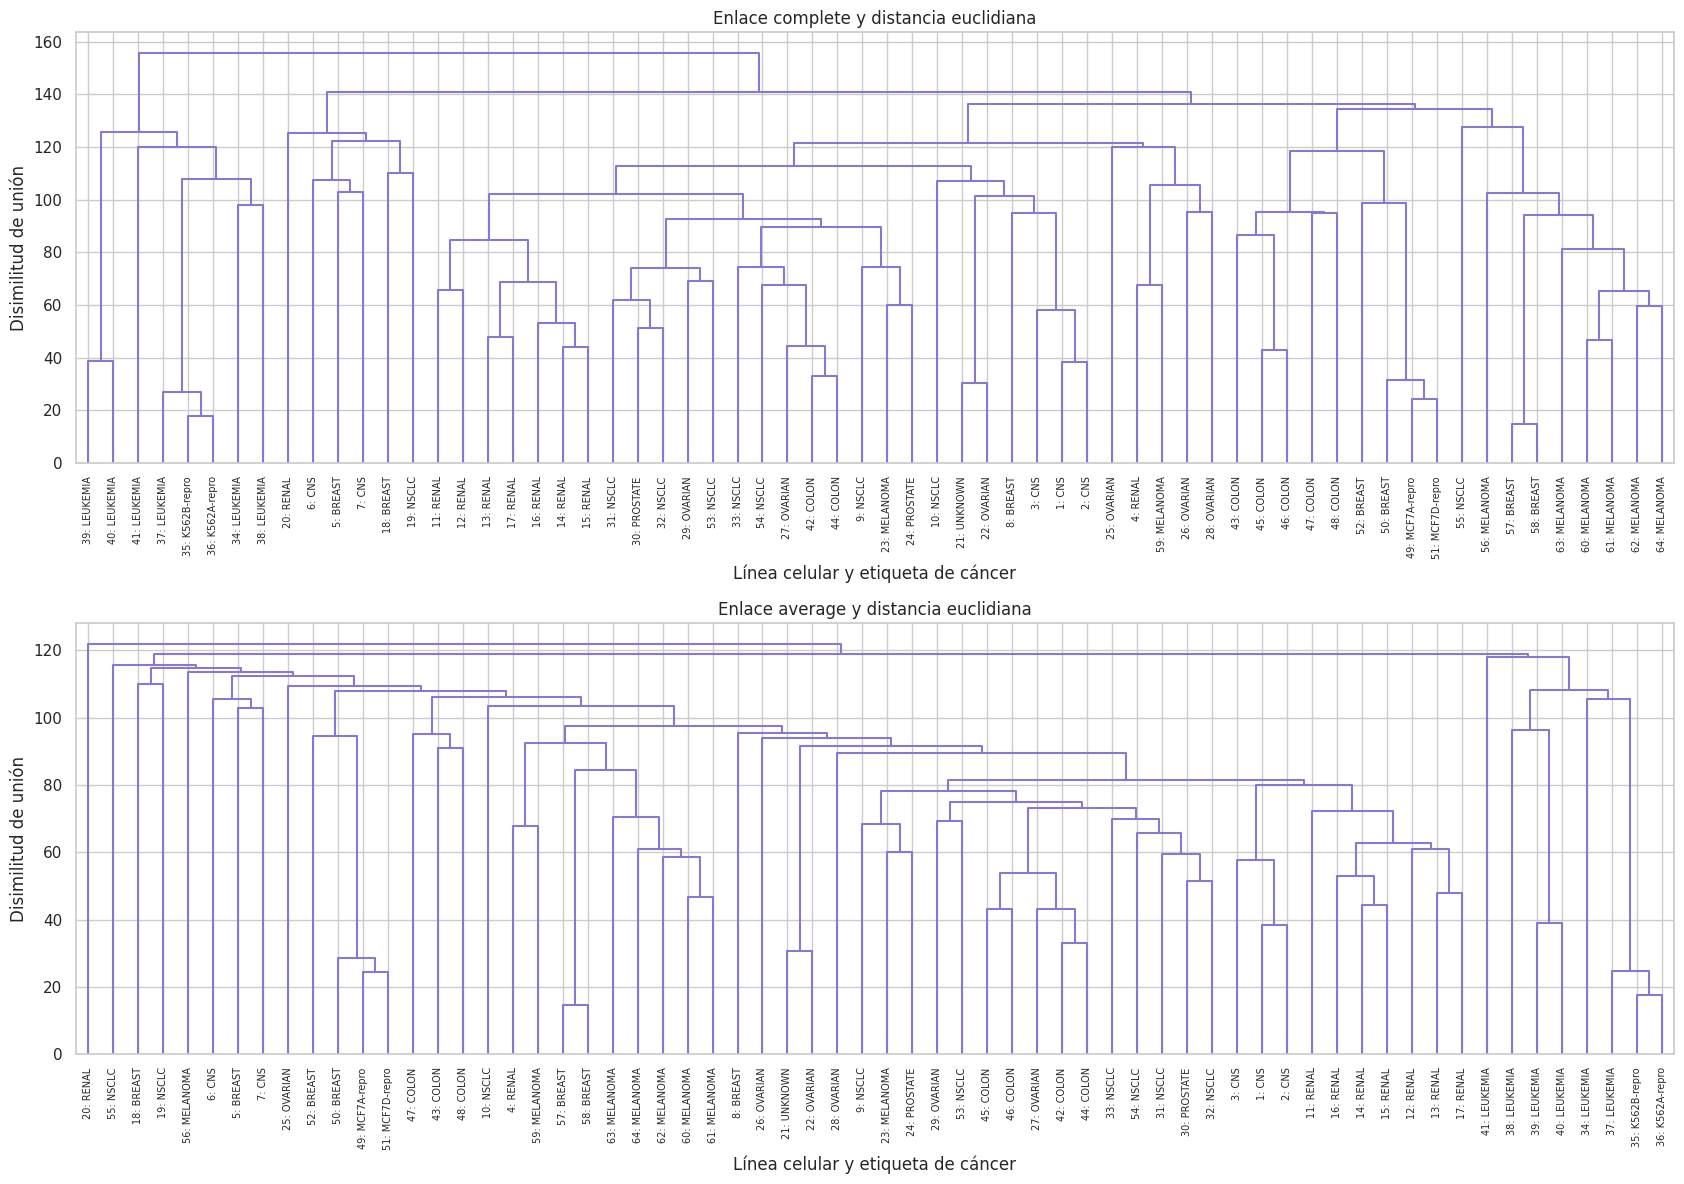

In [45]:
# Construir la jerarquía con enlace average
Z_average_euclidean = linkage(
    X_jerarquico.to_numpy(),
    method="average",
    metric="euclidean"
)

# Comparar ambos métodos de enlace
fig, axes = plt.subplots(2, 1, figsize=(17, 12))

configuraciones_enlace = [
    (
        Z_complete_euclidean,
        "Enlace complete y distancia euclidiana"
    ),
    (
        Z_average_euclidean,
        "Enlace average y distancia euclidiana"
    )
]

for ax, (matriz_enlaces, titulo) in zip(
    axes, configuraciones_enlace
):

    dendrogram(
        matriz_enlaces,
        labels=etiquetas_dendrograma,
        leaf_rotation=90,
        leaf_font_size=7,
        link_color_func=lambda _: "#8C78C8",
        ax=ax
    )

    ax.set_title(titulo)
    ax.set_xlabel("Línea celular y etiqueta de cáncer")
    ax.set_ylabel("Disimilitud de unión")

plt.tight_layout()
plt.show()

Al cambiar el enlace complete por average, se modifica el orden en que se unen los grupos. Con complete se observan ramas grandes más diferenciadas, mientras que con average varias observaciones y grupos pequeños se incorporan progresivamente a una rama principal.

Algunas agrupaciones se mantienen, como los pares K562A-repro y K562B-repro, MCF7A-repro y MCF7D-repro, y varios subgrupos de MELANOMA. Esto indica que ciertas similitudes se conservan, aunque cambie la estructura general del árbol.

La última unión ocurre cerca de 156 con complete y de 122 con average. Esta diferencia no demuestra que average sea mejor: complete utiliza la mayor distancia entre puntos de ambos grupos, mientras que average utiliza el promedio. Por lo tanto, el criterio de enlace influye tanto en las alturas como en los grupos obtenidos.

## Conclusiones
En esta actividad se aplicaron K-means y clustering jerárquico para identificar grupos de observaciones sin utilizar las etiquetas de cáncer durante el agrupamiento. Con los datos sintéticos se observó cómo K-means actualiza las asignaciones y los centroides hasta que dejan de cambiar. También se comprobó que distintas inicializaciones pueden producir resultados similares, aunque esto no garantiza encontrar siempre la mejor solución.

En la base NCI60, PCA permitió reducir las variables genéticas a 32 componentes que conservaron al menos el 80 % de la variación. Las gráficas de los primeros componentes facilitaron la visualización de diferencias que no eran claras al utilizar pares de variables individuales. Al aplicar K-means con los componentes seleccionados se obtuvieron cinco clusters, con coincidencias parciales respecto a las etiquetas originales. Por ejemplo, todas las observaciones de COLON quedaron en un mismo grupo, mientras que BREAST se distribuyó entre varios.

El mapa de calor permitió identificar variables con diferencias de expresión promedio entre dos clusters. Sin embargo, estas diferencias tienen un alcance descriptivo: no demuestran significancia estadística ni permiten considerar las variables como marcadores de cáncer sin análisis adicionales.

Por su parte, el clustering jerárquico mostró cómo las observaciones se organizan en grupos anidados. Al disminuir la altura del corte se obtuvieron más clusters, y al cambiar la distancia o el método de enlace se modificó la estructura del árbol. Algunas agrupaciones se conservaron, lo que indica similitudes consistentes bajo las configuraciones exploradas.

Los resultados muestran que el agrupamiento depende del preprocesamiento, la representación de los datos y las decisiones del método. K-means permite obtener una partición para un número de grupos establecido, mientras que el clustering jerárquico permite explorar diferentes niveles de agrupación. Ambos aportan información útil sobre la estructura de los datos, pero los clusters deben interpretarse como patrones exploratorios y no como categorías biológicas definitivas.